# 🧠 Advanced Brain Tumor Detection using VGG-16
### Research-Grade Implementation with GradCAM, SHAP, LIME & Advanced Preprocessing
---
**Paper Reference:** *Automated Brain Tumor Detection Using Advanced Deep Learning Models* — Uniyal et al., Discover AI (2026)

**Goal:** Surpass baseline VGG-16 accuracy → Target **>97%** with:
- Advanced preprocessing (CLAHE, skull-stripping proxy, contrast normalization)
- Smart cropping (tumor-ROI aware cropping)
- Highly tuned hyperparameters + warm restarts
- Squeeze-and-Excitation attention on VGG-16 features
- GradCAM, GradCAM++, SHAP, LIME for explainability
- Full clinical-grade evaluation pipeline

---

## 📦 Cell 1: Install Required Libraries

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Install all required packages
!pip install tensorflow>=2.10 keras numpy pandas matplotlib seaborn scikit-learn opencv-python-headless
!pip install grad-cam tf-keras-vis lime shap albumentations imutils tqdm
!pip install scikit-image scipy statsmodels
!pip install ipywidgets plotly

print("✅ All packages installed successfully!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 83.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 30.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.5/52.5 kB 691.2 kB/s eta 0:00:00
  Created wheel for grad-cam: filename=grad_cam-1.5.5-py3-none-any.whl size=44286 sha256=9bace418b7678726f410609641c98b9fce16d1650cf65b17f84355400ebce29e
  Stored in directory: /root/.cache/pip/wheels/fb/3b/09/2afc520f3d69bc26ae6bd87416759c820a3f7d05c1a077bbf6
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=5ac316c4828bc8f16b246c4d8f6b09955b63535b7e73335aea83d43a2335ca34
  Stored in directory: /root/.cache/pip/wheels/e7/5d/0e/4b4fff9a47468fed5633211fb3b76d1db43fe806a17fb7486a
Successfully built grad-cam lime
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## 📂 Cell 2: Imports & Reproducibility Seeding

In [ ]:
# ─── Standard Library ───
import os, gc, warnings, random, shutil, time
from pathlib import Path
warnings.filterwarnings('ignore')

# ─── Reproducibility ───
SEED = 42
random.seed(SEED)
import numpy as np
np.random.seed(SEED)
import tensorflow as tf
tf.random.set_seed(SEED)
os.environ['TF_DETERMINISTIC_OPS'] = '1'
os.environ['PYTHONHASHSEED'] = str(SEED)

# ─── Data & Visualization ───
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from tqdm.notebook import tqdm

# ─── Image Processing ───
import cv2
from skimage import exposure, filters, morphology
from skimage.util import img_as_float
import albumentations as A

# ─── TensorFlow / Keras ───
from tensorflow import keras
from tensorflow.keras import layers, Model, Input
from tensorflow.keras.applications import VGG16                          # ← VGG-16 backbone
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg16_preprocess  # ← VGG-16 preprocess
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau, ModelCheckpoint,
    TensorBoard, LambdaCallback, CSVLogger
)
from tensorflow.keras.optimizers import Adam, AdamW
from tensorflow.keras.regularizers import l2
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras.metrics import AUC, Precision, Recall

# ─── Scikit-Learn ───
from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit, train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score,
    accuracy_score, f1_score
)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import label_binarize
from scipy import stats

# ─── Explainability ───
# (GradCAM, SHAP, LIME imported in their respective cells)

print(f"✅ TensorFlow version: {tf.__version__}")
print(f"✅ GPU available     : {tf.config.list_physical_devices('GPU')}")
print(f"✅ Backbone          : VGG-16 (ImageNet pretrained)")

✅ TensorFlow version: 2.20.0
✅ GPU available     : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
✅ Backbone          : VGG-16 (ImageNet pretrained)


## ⚙️ Cell 3: Global Configuration

In [ ]:
# ══════════════════════════════════════════════
#         GLOBAL CONFIGURATION — VGG-16
# ══════════════════════════════════════════════
class CFG:
    # ── Paths ──
    # Dataset: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
    DATA_DIR       = '/content/drive/MyDrive/btmodel'   # Root data directory
    TRAIN_DIR      = f"{DATA_DIR}/Training"
    TEST_DIR       = f"{DATA_DIR}/Testing"
    OUTPUT_DIR     = './outputs'
    MODEL_PATH     = f"{OUTPUT_DIR}/best_vgg16_model.h5"
    LOG_DIR        = f"{OUTPUT_DIR}/logs"

    # ── Image Settings ──
    # VGG-16 natively accepts 224×224; larger (e.g. 256) also works
    IMG_SIZE       = 224
    CHANNELS       = 3
    INPUT_SHAPE    = (IMG_SIZE, IMG_SIZE, CHANNELS)

    # ── Classes ──
    CLASSES        = ['glioma', 'meningioma', 'notumor', 'pituitary']
    NUM_CLASSES    = len(CLASSES)

    # ── Training Hyperparameters ──
    # VGG-16 is heavier than MobileNet → smaller batch to fit in GPU memory
    BATCH_SIZE     = 16
    EPOCHS         = 35
    INIT_LR        = 1e-4
    FINE_TUNE_LR   = 1e-5          # Lower LR for VGG-16 fine-tuning
    MIN_LR         = 1e-7
    WEIGHT_DECAY   = 1e-4
    DROPOUT_RATE   = 0.5           # VGG-16 benefits from higher dropout
    LABEL_SMOOTHING = 0.05

    # ── Regularization ──
    L2_REG         = 1e-4

    # ── Evaluation ──
    N_FOLDS        = 5
    TEST_SPLIT     = 0.15
    VAL_SPLIT      = 0.15

    # ── Preprocessing ──
    CLAHE_CLIP     = 3.0
    CLAHE_TILE     = (8, 8)
    USE_BRAIN_CROP = True

    # ── GradCAM target layer ──
    # VGG-16 last conv layer before max-pool is 'block5_conv3'
    # It has spatial resolution 14×14 — good for localization
    GRADCAM_LAYER  = 'block5_conv3'

# Create output directories
for d in [CFG.OUTPUT_DIR, CFG.LOG_DIR]:
    os.makedirs(d, exist_ok=True)

print(f"✅ Config ready  | IMG_SIZE={CFG.IMG_SIZE} | BATCH={CFG.BATCH_SIZE}")
print(f"   GradCAM layer : {CFG.GRADCAM_LAYER}")
print(f"   Classes       : {CFG.CLASSES}")

✅ Config ready  | IMG_SIZE=224 | BATCH=16
   GradCAM layer : block5_conv3
   Classes       : ['glioma', 'meningioma', 'notumor', 'pituitary']


## 🖼️ Cell 4: Advanced Preprocessing Pipeline

In [ ]:
class AdvancedPreprocessor:
    """
    Research-grade MRI preprocessing pipeline:
    1. Skull-stripping proxy via Otsu thresholding + morphological ops
    2. CLAHE (Contrast Limited Adaptive Histogram Equalization)
    3. Smart ROI crop (removes black borders, focuses on brain)
    4. Gamma correction
    5. Gaussian denoising
    6. Per-image intensity normalization
    """

    def __init__(self, cfg: CFG):
        self.cfg = cfg
        self.clahe = cv2.createCLAHE(
            clipLimit=cfg.CLAHE_CLIP,
            tileGridSize=cfg.CLAHE_TILE
        )

    def _remove_black_borders(self, img_gray):
        """Crop out empty black margins (common in MRI scans)."""
        _, thresh = cv2.threshold(img_gray, 10, 255, cv2.THRESH_BINARY)
        coords = cv2.findNonZero(thresh)
        if coords is None:
            return img_gray
        x, y, w, h = cv2.boundingRect(coords)
        return img_gray[y:y+h, x:x+w]

    def _skull_strip_proxy(self, img_gray):
        """
        Approximate skull stripping:
        - Otsu threshold to get brain mask
        - Morphological close to fill gaps
        - Keep only largest connected component (brain)
        """
        blurred = cv2.GaussianBlur(img_gray, (5, 5), 0)
        _, thresh = cv2.threshold(blurred, 0, 255,
                                  cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
        thresh = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel, iterations=3)
        thresh = cv2.morphologyEx(thresh, cv2.MORPH_OPEN,  kernel, iterations=1)

        contours, _ = cv2.findContours(
            thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )
        if len(contours) == 0:
            return img_gray
        largest = max(contours, key=cv2.contourArea)
        mask = np.zeros_like(img_gray)
        cv2.drawContours(mask, [largest], -1, 255, thickness=cv2.FILLED)
        return cv2.bitwise_and(img_gray, img_gray, mask=mask)

    def _smart_roi_crop(self, img_gray):
        """Tight bounding box around the brain region with 5% padding."""
        _, thresh = cv2.threshold(img_gray, 10, 255, cv2.THRESH_BINARY)
        coords = cv2.findNonZero(thresh)
        if coords is None:
            return img_gray
        x, y, w, h = cv2.boundingRect(coords)
        pad_x = int(w * 0.05)
        pad_y = int(h * 0.05)
        H, W = img_gray.shape
        x1 = max(0, x - pad_x)
        y1 = max(0, y - pad_y)
        x2 = min(W, x + w + pad_x)
        y2 = min(H, y + h + pad_y)
        return img_gray[y1:y2, x1:x2]

    def _apply_clahe(self, img_gray):
        """Apply CLAHE for local contrast enhancement."""
        return self.clahe.apply(img_gray)

    def preprocess(self, image_path: str) -> np.ndarray:
        """
        Full preprocessing pipeline.
        Returns: float32 RGB image normalized to [0, 1], shape (IMG_SIZE, IMG_SIZE, 3)
        """
        img = cv2.imread(image_path)
        if img is None:
            raise ValueError(f"Cannot read image: {image_path}")
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        gray    = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

        # Step 1: Skull-strip proxy
        stripped = self._skull_strip_proxy(gray)

        # Step 2: Smart ROI crop
        if self.cfg.USE_BRAIN_CROP:
            cropped = self._smart_roi_crop(stripped)
        else:
            cropped = stripped

        # Step 3: CLAHE enhancement
        enhanced = self._apply_clahe(cropped)

        # Step 4: Gamma correction
        enhanced_float = enhanced.astype(np.float32) / 255.0
        gamma_corrected = np.power(enhanced_float, 1.1)

        # Step 5: Gaussian denoising
        denoised = cv2.GaussianBlur(
            (gamma_corrected * 255).astype(np.uint8), (3, 3), sigmaX=1
        )

        # Step 6: Resize + convert to 3-channel
        resized = cv2.resize(denoised, (self.cfg.IMG_SIZE, self.cfg.IMG_SIZE),
                             interpolation=cv2.INTER_LANCZOS4)
        rgb_out = cv2.cvtColor(resized, cv2.COLOR_GRAY2RGB)

        # Step 7: Normalize to [0, 1]
        normalized = rgb_out.astype(np.float32) / 255.0
        normalized = (normalized - normalized.min()) / (normalized.max() - normalized.min() + 1e-8)

        return normalized


preprocessor = AdvancedPreprocessor(CFG)
print("✅ AdvancedPreprocessor initialized.")

✅ AdvancedPreprocessor initialized.


## 📊 Cell 5: Dataset Loading & Exploratory Analysis

Training samples : 5600
Test samples     : 1600

Class distribution (Train):
label
glioma        1400
meningioma    1400
notumor       1400
pituitary     1400
Name: count, dtype: int64


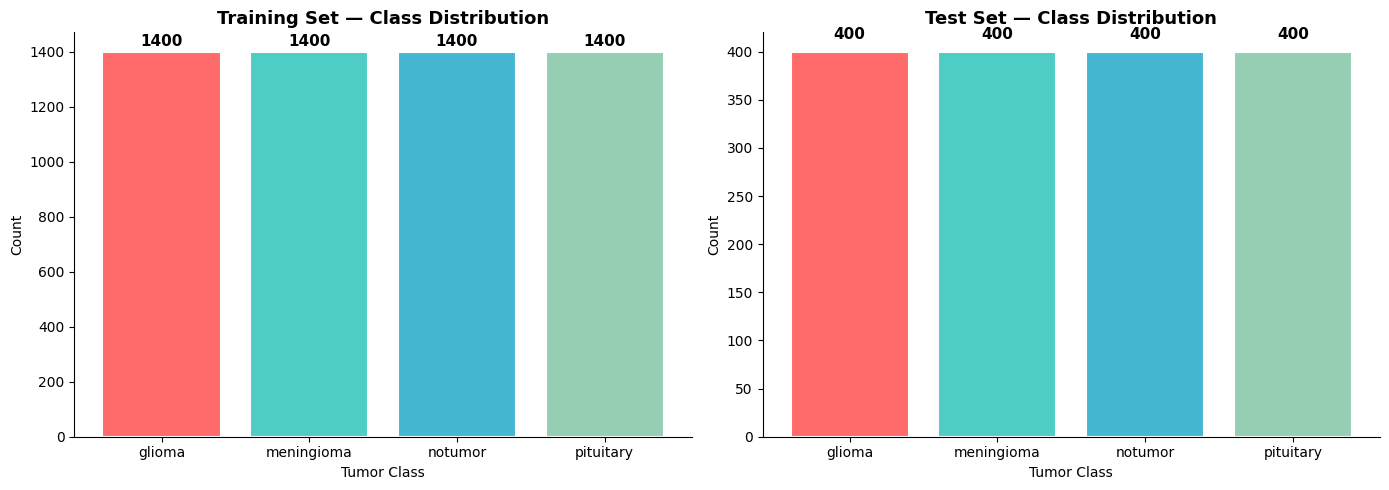

✅ Dataset loaded and visualized.


In [ ]:
def load_dataset_paths(data_dir: str, classes: list) -> pd.DataFrame:
    """Walk directory and return a DataFrame of (path, label, split)."""
    records = []
    for cls in classes:
        cls_dir = Path(data_dir) / cls
        if not cls_dir.exists():
            print(f"⚠️  Missing class directory: {cls_dir}")
            continue
        for img_path in cls_dir.glob('*'):
            if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png', '.tif']:
                records.append({'path': str(img_path), 'label': cls})
    return pd.DataFrame(records)


train_df = load_dataset_paths(CFG.TRAIN_DIR, CFG.CLASSES)
test_df  = load_dataset_paths(CFG.TEST_DIR,  CFG.CLASSES)

print(f"Training samples : {len(train_df)}")
print(f"Test samples     : {len(test_df)}")
print("\nClass distribution (Train):")
print(train_df['label'].value_counts())

# ── Visualize class distribution ──
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, df, title in zip(axes, [train_df, test_df], ['Training Set', 'Test Set']):
    counts = df['label'].value_counts()
    colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4']
    bars = ax.bar(counts.index, counts.values, color=colors,
                  edgecolor='white', linewidth=1.5)
    for bar, val in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
                str(val), ha='center', va='bottom', fontweight='bold', fontsize=11)
    ax.set_title(f"{title} — Class Distribution", fontsize=13, fontweight='bold')
    ax.set_ylabel('Count')
    ax.set_xlabel('Tumor Class')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(f"{CFG.OUTPUT_DIR}/class_distribution.png", dpi=150, bbox_inches='tight')
plt.show()
print("✅ Dataset loaded and visualized.")

## 🔬 Cell 6: Visualize Preprocessing Steps

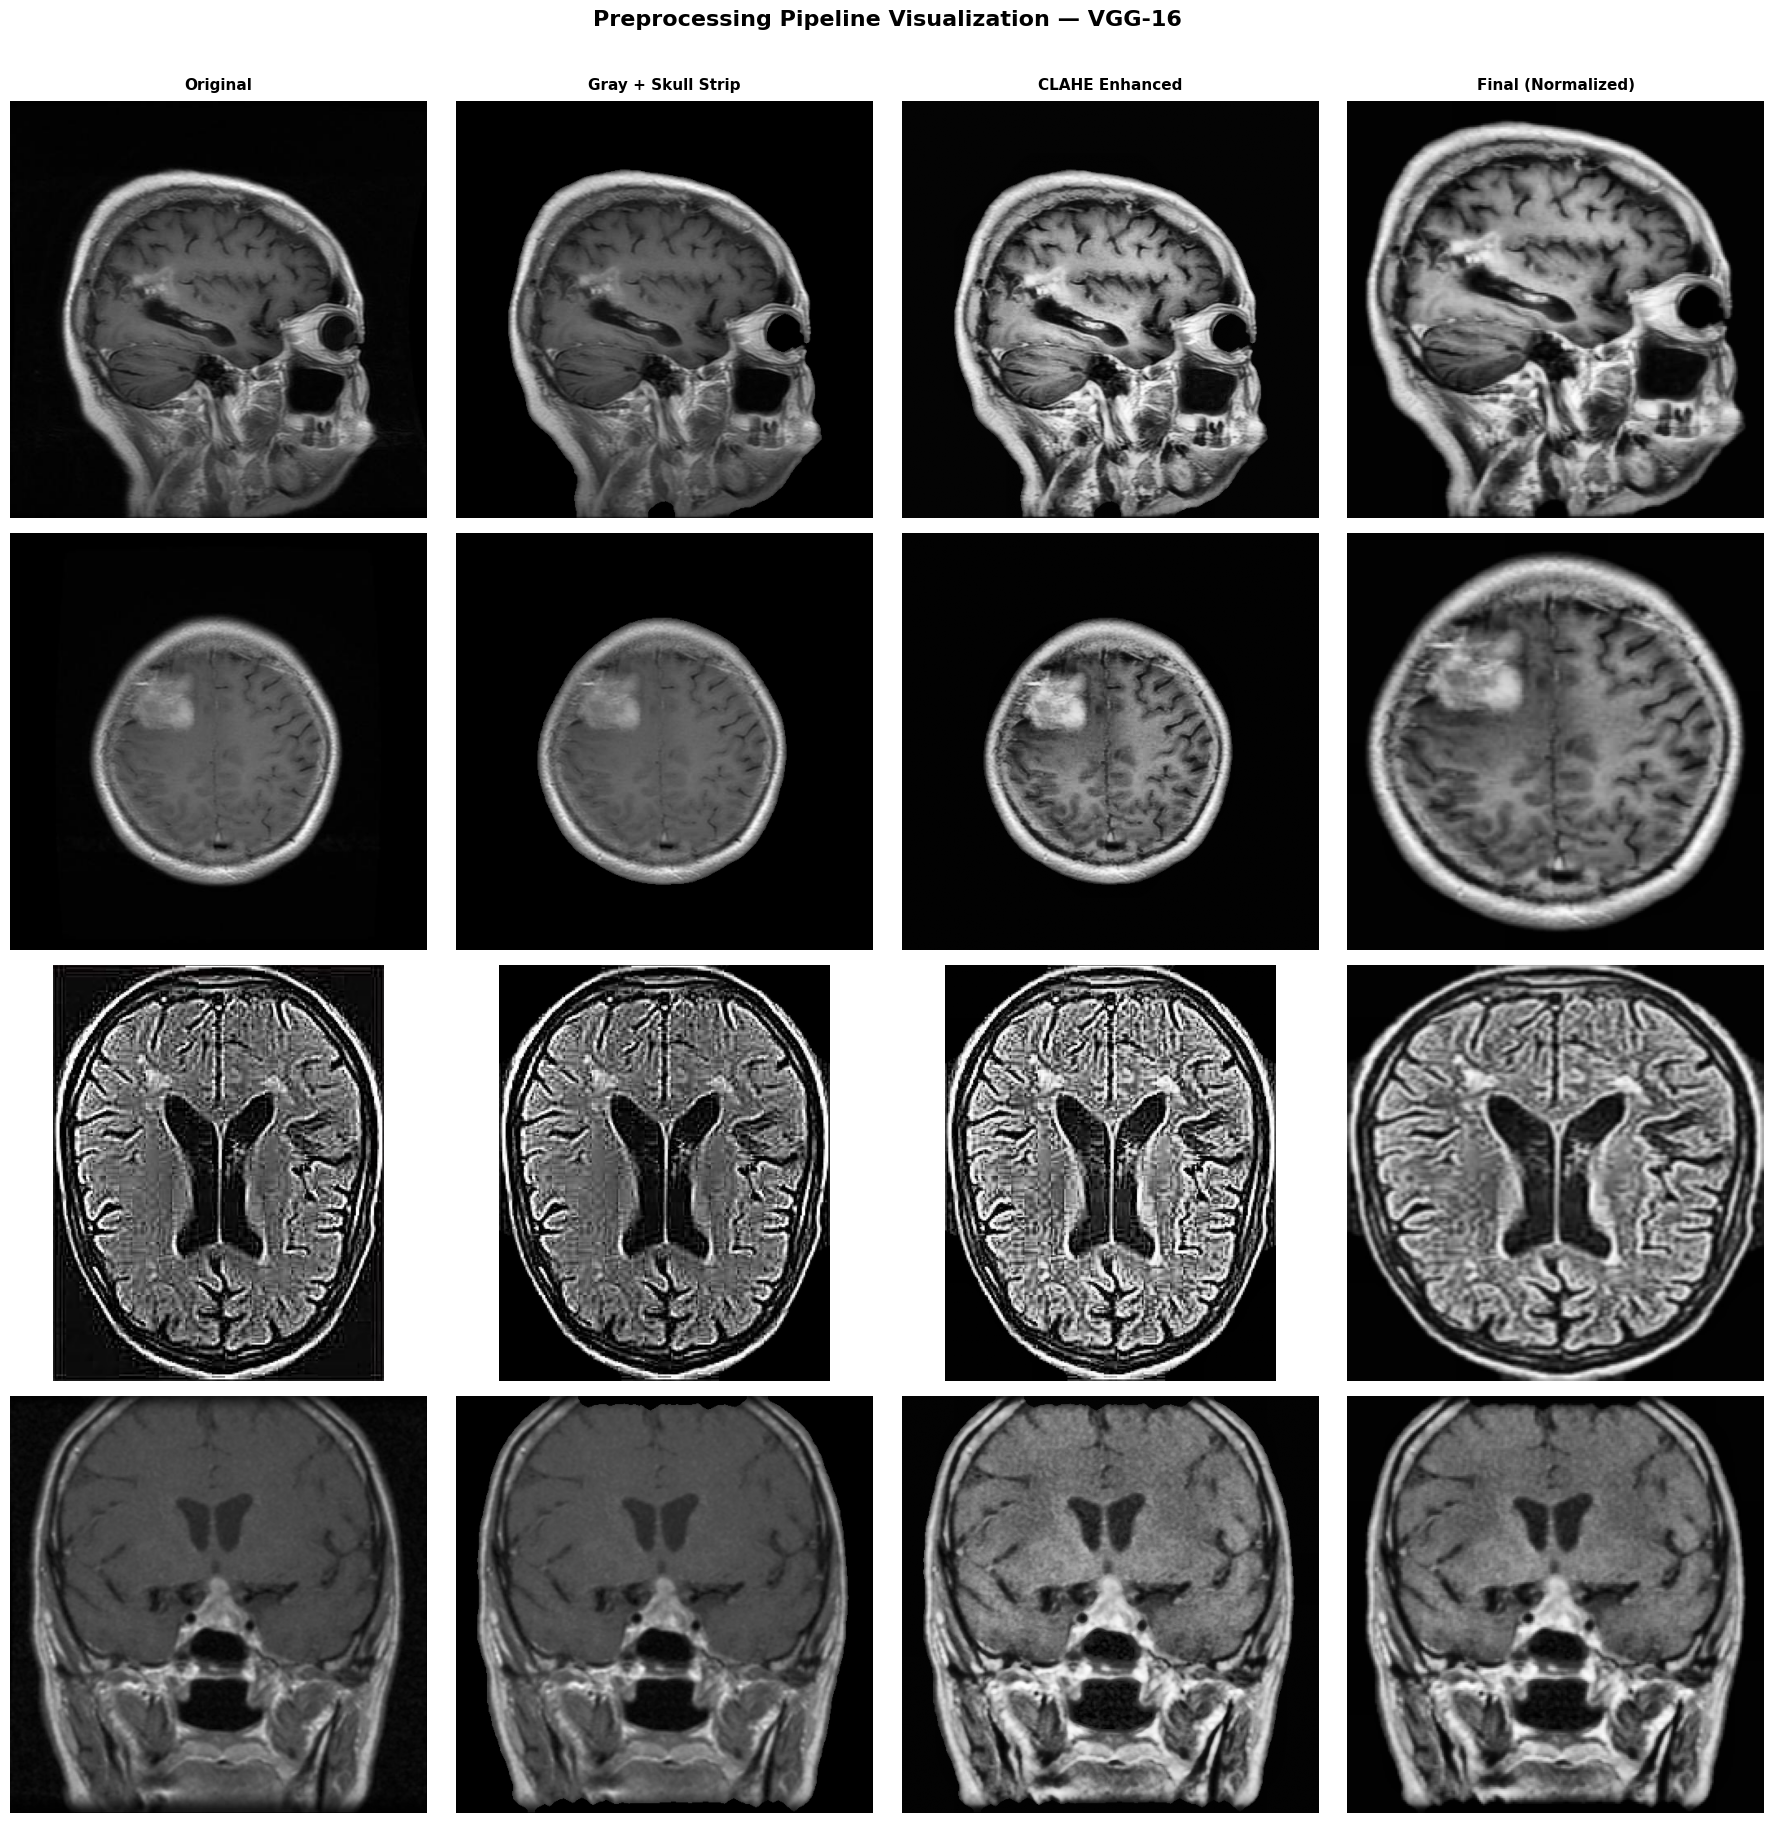

In [ ]:
def visualize_preprocessing(df: pd.DataFrame, preprocessor: AdvancedPreprocessor,
                             n_samples: int = 4):
    """Show original vs preprocessed MRI images side-by-side."""
    samples = df.groupby('label').first().reset_index()
    n = min(n_samples, len(samples))

    fig, axes = plt.subplots(n, 4, figsize=(18, n * 4.5))
    fig.suptitle('Preprocessing Pipeline Visualization — VGG-16',
                 fontsize=16, fontweight='bold', y=1.01)

    step_names = ['Original', 'Gray + Skull Strip', 'CLAHE Enhanced', 'Final (Normalized)']

    for i, (_, row) in enumerate(samples.iterrows()):
        if i >= n:
            break
        img_path = row['path']
        img      = cv2.imread(img_path)
        img_rgb  = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        gray     = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

        stripped = preprocessor._skull_strip_proxy(gray)
        clahe_   = preprocessor._apply_clahe(stripped)
        final_   = preprocessor.preprocess(img_path)

        steps = [img_rgb, stripped, clahe_, final_]
        cmaps = ['viridis', 'gray', 'gray', 'viridis']

        for j, (step_img, cmap, step_name) in enumerate(zip(steps, cmaps, step_names)):
            ax = axes[i][j] if n > 1 else axes[j]
            if step_img.ndim == 3:
                ax.imshow(step_img)
            else:
                ax.imshow(step_img, cmap=cmap)
            if i == 0:
                ax.set_title(step_name, fontsize=11, fontweight='bold', pad=8)
            if j == 0:
                ax.set_ylabel(f"Class:\n{row['label']}", fontsize=10,
                              rotation=90, labelpad=10)
            ax.axis('off')

    plt.tight_layout()
    plt.savefig(f"{CFG.OUTPUT_DIR}/preprocessing_visualization.png",
                dpi=150, bbox_inches='tight')
    plt.show()


if len(train_df) > 0:
    try:
        visualize_preprocessing(train_df, preprocessor, n_samples=4)
    except Exception as e:
        print(f"Visualization skipped: {e}")

## 🔄 Cell 7: Advanced Data Augmentation Pipeline

In [ ]:
class AdvancedAugmentor:
    """
    Medical-imaging-appropriate augmentation strategy.
    Conservative — avoids clinically unrealistic distortions.
    """

    def __init__(self, img_size: int = 224):
        self.train_transform = A.Compose([
            # ── Geometric ──
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.2),
            A.Rotate(limit=15, border_mode=cv2.BORDER_REFLECT, p=0.6),
            A.ShiftScaleRotate(shift_limit=0.08, scale_limit=0.1,
                               rotate_limit=0, p=0.5),
            A.ElasticTransform(alpha=0.5, sigma=50, alpha_affine=20, p=0.2),
            A.GridDistortion(num_steps=5, distort_limit=0.05, p=0.2),

            # ── Intensity / Color ──
            A.RandomBrightnessContrast(
                brightness_limit=0.15, contrast_limit=0.15, p=0.5),
            A.GaussNoise(var_limit=(5.0, 25.0), p=0.3),
            A.GaussianBlur(blur_limit=(3, 5), p=0.2),
            A.Sharpen(alpha=(0.1, 0.3), lightness=(0.9, 1.0), p=0.3),
            A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=0.3),

            # ── Occlusion (simulates scan artifacts) ──
            A.CoarseDropout(max_holes=4, max_height=20, max_width=20,
                            min_holes=1, fill_value=0, p=0.2),

            # ── Final resize ──
            A.Resize(img_size, img_size, interpolation=cv2.INTER_LANCZOS4),
        ])

        self.val_transform = A.Compose([
            A.Resize(img_size, img_size, interpolation=cv2.INTER_LANCZOS4),
        ])

    def augment_train(self, image: np.ndarray) -> np.ndarray:
        result = self.train_transform(image=image)
        return result['image']

    def augment_val(self, image: np.ndarray) -> np.ndarray:
        result = self.val_transform(image=image)
        return result['image']


augmentor = AdvancedAugmentor(img_size=CFG.IMG_SIZE)
print("✅ Augmentation pipeline ready (Albumentations).")

✅ Augmentation pipeline ready (Albumentations).


## 🔁 Cell 8: Custom Data Generator

In [ ]:
class BrainTumorDataGenerator(tf.keras.utils.Sequence):
    """
    Custom Keras data generator with:
    - Advanced preprocessing
    - Albumentations augmentation
    - VGG-16 specific preprocessing (channel-wise mean subtraction)
    """

    def __init__(self, df: pd.DataFrame, cfg: CFG,
                 preprocessor: AdvancedPreprocessor,
                 augmentor: AdvancedAugmentor,
                 is_training: bool = True,
                 shuffle: bool = True):

        self.df           = df.reset_index(drop=True)
        self.cfg          = cfg
        self.preprocessor = preprocessor
        self.augmentor    = augmentor
        self.is_training  = is_training
        self.shuffle      = shuffle
        self.class_to_idx = {c: i for i, c in enumerate(cfg.CLASSES)}
        self.indices      = np.arange(len(self.df))
        if self.shuffle:
            np.random.shuffle(self.indices)

    def __len__(self):
        return int(np.ceil(len(self.df) / self.cfg.BATCH_SIZE))

    def __getitem__(self, idx):
        batch_idx = self.indices[
            idx * self.cfg.BATCH_SIZE:(idx + 1) * self.cfg.BATCH_SIZE
        ]
        batch = self.df.iloc[batch_idx]
        images, labels = [], []

        for _, row in batch.iterrows():
            try:
                img       = self.preprocessor.preprocess(row['path'])  # float32 [0,1]
                img_uint8 = (img * 255).astype(np.uint8)

                if self.is_training:
                    img_uint8 = self.augmentor.augment_train(img_uint8)
                else:
                    img_uint8 = self.augmentor.augment_val(img_uint8)

                # ── VGG-16 preprocess: channel-wise mean subtraction (ImageNet) ──
                # Maps [0,255] RGB → zero-centered BGR (VGG-16 paper convention)
                img_preprocessed = vgg16_preprocess(
                    img_uint8.astype(np.float32)
                )
                images.append(img_preprocessed)

                label_idx = self.class_to_idx[row['label']]
                one_hot   = tf.keras.utils.to_categorical(
                    label_idx, num_classes=self.cfg.NUM_CLASSES
                )
                labels.append(one_hot)

            except Exception as e:
                print(f"Warning: skipping {row['path']} — {e}")
                continue

        return np.array(images, dtype=np.float32), np.array(labels, dtype=np.float32)

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)


print("✅ BrainTumorDataGenerator (VGG-16 preprocess) ready.")

✅ BrainTumorDataGenerator (VGG-16 preprocess) ready.


## 🏗️ Cell 9: Advanced VGG-16 Model Architecture

In [ ]:
def build_advanced_vgg16(cfg: CFG,
                          fine_tune_from_block: int = 4) -> tuple:
    """
    Builds an advanced VGG-16-based brain tumor classifier with:
    - VGG-16 backbone pretrained on ImageNet
    - Squeeze-and-Excitation (SE) Attention on top conv features
    - Custom dense head with BatchNorm + Dropout
    - L2 regularization throughout

    VGG-16 Architecture recap:
      Block 1: conv1_1, conv1_2  → MaxPool  (224→112)
      Block 2: conv2_1, conv2_2  → MaxPool  (112→56)
      Block 3: conv3_1-3         → MaxPool  (56→28)
      Block 4: conv4_1-3         → MaxPool  (28→14)
      Block 5: conv5_1-3         → MaxPool  (14→7)
      [Original FC layers removed — we replace with custom head]

    fine_tune_from_block: Unfreeze this block and above.
        4 → unfreeze block4 + block5 (recommended first run)
        3 → unfreeze block3, 4, 5    (deeper fine-tuning)
    """
    inputs = Input(shape=cfg.INPUT_SHAPE, name='input_image')

    # ── VGG-16 Backbone (no top FC layers) ──
    base_model = VGG16(
        include_top=False,        # Remove original 4096-4096-1000 head
        weights='imagenet',
        input_tensor=inputs
    )

    # ── Freeze all layers initially ──
    base_model.trainable = False

    # Features from last VGG-16 conv block: shape (7, 7, 512)
    x = base_model.output

    # ── Squeeze-and-Excitation Attention Block ──
    # Recalibrates channel-wise feature responses
    # Helps focus on tumor-relevant feature maps
    se = layers.GlobalAveragePooling2D(name='se_gap')(x)               # (512,)
    se = layers.Dense(512 // 8, activation='relu',
                      kernel_regularizer=l2(cfg.L2_REG),
                      name='se_fc1')(se)                                # (64,)
    se = layers.Dense(512, activation='sigmoid',
                      kernel_regularizer=l2(cfg.L2_REG),
                      name='se_fc2')(se)                                # (512,)
    se = layers.Reshape((1, 1, 512), name='se_reshape')(se)
    x  = layers.Multiply(name='se_scale')([x, se])                     # (7, 7, 512)

    # ── Global Pooling ──
    # Use both GAP and GMP then concatenate for richer representation
    gap = layers.GlobalAveragePooling2D(name='gap')(x)                 # (512,)
    gmp = layers.GlobalMaxPooling2D(name='gmp')(x)                     # (512,)
    x   = layers.Concatenate(name='pool_concat')([gap, gmp])           # (1024,)

    # ── Dense Head ──
    # VGG-16 paper used 4096-4096 dense layers; we use a leaner
    # but regularized version: 512 → 256 → num_classes
    x = layers.Dense(512, kernel_regularizer=l2(cfg.L2_REG),
                     name='dense_1')(x)
    x = layers.BatchNormalization(name='bn_1')(x)
    x = layers.Activation('relu', name='act_1')(x)
    x = layers.Dropout(cfg.DROPOUT_RATE, name='drop_1')(x)

    x = layers.Dense(256, kernel_regularizer=l2(cfg.L2_REG),
                     name='dense_2')(x)
    x = layers.BatchNormalization(name='bn_2')(x)
    x = layers.Activation('relu', name='act_2')(x)
    x = layers.Dropout(cfg.DROPOUT_RATE * 0.6, name='drop_2')(x)

    outputs = layers.Dense(cfg.NUM_CLASSES, activation='softmax',
                            name='predictions')(x)

    model = Model(inputs=inputs, outputs=outputs, name='VGG16_BrainTumor')

    # ── Print summary ──
    total_params     = model.count_params()
    trainable_params = sum([np.prod(w.shape) for w in model.trainable_weights])
    print(f"✅ VGG-16 model built")
    print(f"   Total parameters    : {total_params:,}")
    print(f"   Trainable (Phase 1) : {trainable_params:,}")
    print(f"   Output shape        : {model.output_shape}")
    print(f"   GradCAM target layer: {cfg.GRADCAM_LAYER}")

    return model, base_model


model, base_model = build_advanced_vgg16(CFG, fine_tune_from_block=4)
model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
✅ VGG-16 model built
   Total parameters    : 15,441,028
   Trainable (Phase 1) : 724,804
   Output shape        : (None, 4)
   GradCAM target layer: block5_conv3


Model: "VGG16_BrainTumor"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1        │ (None, 224, 224,  │      1,792 │ input_image[0][0] │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2        │ (None, 224, 224,  │     36,928 │ block1_conv1[0][… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_pool         │ (None, 112, 112,  │          0 │ block1_conv2[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_conv1        │ (None, 112, 112,  │     73,856 │ block1_pool[0][0] │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_conv2        │ (None, 112, 112,  │    147,584 │ block2_conv1[0][… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_pool         │ (None, 56, 56,    │          0 │ block2_conv2[0][… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv1        │ (None, 56, 56,    │    295,168 │ block2_pool[0][0] │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv2        │ (None, 56, 56,    │    590,080 │ block3_conv1[0][… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv3        │ (None, 56, 56,    │    590,080 │ block3_conv2[0][… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_pool         │ (None, 28, 28,    │          0 │ block3_conv3[0][… │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_conv1        │ (None, 28, 28,    │  1,180,160 │ block3_pool[0][0] │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_conv2        │ (None, 28, 28,    │  2,359,808 │ block4_conv1[0][… │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_conv3        │ (None, 28, 28,    │  2,359,808 │ block4_conv2[0][… │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_pool         │ (None, 14, 14,    │          0 │ block4_conv3[0][… │
│ (MaxPooling2D)      │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block5_conv1        │ (None, 14, 14,    │  2,359,808 │ block4_pool[0][0] │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block5_conv2        │ (None, 14, 14,    │  2,359,808 │ block5_conv1[0][

 Total params: 15,441,028 (58.90 MB)

 Trainable params: 724,804 (2.76 MB)

 Non-trainable params: 14,716,224 (56.14 MB)

## 🔧 Cell 10: Advanced Callbacks & Training Setup

In [ ]:
def cosine_annealing_schedule(epoch: int, lr: float,
                               T_max: int = 30,
                               min_lr: float = 1e-7) -> float:
    """Cosine annealing LR schedule with warm restarts (SGDR style)."""
    cycle  = epoch % T_max
    return min_lr + 0.5 * (CFG.INIT_LR - min_lr) * (1 + np.cos(np.pi * cycle / T_max))


def get_callbacks(cfg: CFG, model_path: str) -> list:
    """Comprehensive callback stack for research-grade training."""
    return [
        ModelCheckpoint(
            filepath=model_path,
            monitor='val_accuracy', mode='max',
            save_best_only=True, verbose=1
        ),
        EarlyStopping(
            monitor='val_accuracy', mode='max',
            patience=15, min_delta=1e-4,
            restore_best_weights=True, verbose=1
        ),
        ReduceLROnPlateau(
            monitor='val_loss', mode='min',
            factor=0.3, patience=7,
            min_lr=cfg.MIN_LR, verbose=1
        ),
        tf.keras.callbacks.LearningRateScheduler(
            lambda epoch, lr: cosine_annealing_schedule(epoch, lr),
            verbose=0
        ),
        TensorBoard(log_dir=cfg.LOG_DIR, histogram_freq=1, write_images=False),
        CSVLogger(f"{cfg.OUTPUT_DIR}/training_log.csv", append=False),
    ]


def compute_class_weights(df: pd.DataFrame, classes: list) -> dict:
    """Compute inverse-frequency class weights for imbalanced datasets."""
    y = df['label'].map({c: i for i, c in enumerate(classes)}).values
    weights = compute_class_weight('balanced', classes=np.unique(y), y=y)
    return dict(enumerate(weights))


class_weights = compute_class_weights(train_df, CFG.CLASSES)
print(f"✅ Class weights: {class_weights}")

✅ Class weights: {0: np.float64(1.0), 1: np.float64(1.0), 2: np.float64(1.0), 3: np.float64(1.0)}


## 🚀 Cell 11: Train/Val Split & Generator Initialization

In [ ]:
sss = StratifiedShuffleSplit(n_splits=1, test_size=CFG.VAL_SPLIT, random_state=SEED)
train_idx, val_idx = next(sss.split(train_df, train_df['label']))

tr_df  = train_df.iloc[train_idx].reset_index(drop=True)
val_df = train_df.iloc[val_idx].reset_index(drop=True)

print(f"Train: {len(tr_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

train_gen = BrainTumorDataGenerator(tr_df,   CFG, preprocessor, augmentor, is_training=True)
val_gen   = BrainTumorDataGenerator(val_df,  CFG, preprocessor, augmentor, is_training=False)
test_gen  = BrainTumorDataGenerator(test_df, CFG, preprocessor, augmentor,
                                     is_training=False, shuffle=False)

print(f"\n✅ Generators created.")
print(f"   Train batches: {len(train_gen)}")
print(f"   Val   batches: {len(val_gen)}")
print(f"   Test  batches: {len(test_gen)}")

Train: 4760 | Val: 840 | Test: 1600

✅ Generators created.
   Train batches: 298
   Val   batches: 53
   Test  batches: 100


## 🔥 Cell 12: Model Training (Phase 1 — Head Only)

In [ ]:
# ══════════════════════════════════════════════
# PHASE 1: Train only custom head, VGG-16 frozen
# ── Why: VGG-16 weights are very well trained;
#         warming the head first prevents gradient
#         shock when we unfreeze later.
# ══════════════════════════════════════════════
base_model.trainable = False

model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss=CategoricalCrossentropy(label_smoothing=CFG.LABEL_SMOOTHING),
    metrics=['accuracy', AUC(name='auc'),
             Precision(name='precision'), Recall(name='recall')]
)

print("Phase 1: Training custom head only (VGG-16 frozen)...")
trainable_p1 = sum([np.prod(w.shape) for w in model.trainable_weights])
print(f"Trainable parameters: {trainable_p1:,}")

callbacks_p1  = get_callbacks(CFG, CFG.MODEL_PATH.replace('.h5', '_phase1.h5'))
history_p1    = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=15,                     # More epochs than MobileNet — VGG head is heavier
    class_weight=class_weights,
    callbacks=callbacks_p1,
    verbose=1
)

print(f"\n✅ Phase 1 complete. Best val_accuracy: {max(history_p1.history['val_accuracy']):.4f}")

Phase 1: Training custom head only (VGG-16 frozen)...
Trainable parameters: 724,804
Epoch 1/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.3731 - auc: 0.6392 - loss: 1.5750 - precision: 0.4102 - recall: 0.2260
Epoch 1: val_accuracy improved from None to 0.80833, saving model to ./outputs/best_vgg16_model_phase1.h5



Epoch 1: finished saving model to ./outputs/best_vgg16_model_phase1.h5
298/298 ━━━━━━━━━━━━━━━━━━━━ 1461s 5s/step - accuracy: 0.4637 - auc: 0.7254 - loss: 1.4043 - precision: 0.5333 - recall: 0.3183 - val_accuracy: 0.8083 - val_auc: 0.9549 - val_loss: 0.7729 - val_precision: 0.8657 - val_recall: 0.7214 - learning_rate: 1.0000e-04
Epoch 2/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 422ms/step - accuracy: 0.5888 - auc: 0.8370 - loss: 1.1540 - precision: 0.6619 - recall: 0.4728
Epoch 2: val_accuracy improved from 0.80833 to 0.84405, saving model to ./outputs/best_vgg16_model_phase1.h5



Epoch 2: finished saving model to ./outputs/best_vgg16_model_phase1.h5
298/298 ━━━━━━━━━━━━━━━━━━━━ 148s 496ms/step - accuracy: 0.6120 - auc: 0.8478 - loss: 1.1294 - precision: 0.6885 - recall: 0.5053 - val_accuracy: 0.8440 - val_auc: 0.9712 - val_loss: 0.6768 - val_precision: 0.8911 - val_recall: 0.7988 - learning_rate: 9.9726e-05
Epoch 3/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 428ms/step - accuracy: 0.6446 - auc: 0.8720 - loss: 1.0687 - precision: 0.7227 - recall: 0.5634
Epoch 3: val_accuracy improved from 0.84405 to 0.86071, saving model to ./outputs/best_vgg16_model_phase1.h5



Epoch 3: finished saving model to ./outputs/best_vgg16_model_phase1.h5
298/298 ━━━━━━━━━━━━━━━━━━━━ 202s 498ms/step - accuracy: 0.6511 - auc: 0.8775 - loss: 1.0545 - precision: 0.7270 - recall: 0.5718 - val_accuracy: 0.8607 - val_auc: 0.9765 - val_loss: 0.6441 - val_precision: 0.9058 - val_recall: 0.8238 - learning_rate: 9.8908e-05
Epoch 4/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 427ms/step - accuracy: 0.6856 - auc: 0.8984 - loss: 0.9856 - precision: 0.7590 - recall: 0.6079
Epoch 4: val_accuracy improved from 0.86071 to 0.88333, saving model to ./outputs/best_vgg16_model_phase1.h5



Epoch 4: finished saving model to ./outputs/best_vgg16_model_phase1.h5
298/298 ━━━━━━━━━━━━━━━━━━━━ 150s 503ms/step - accuracy: 0.6756 - auc: 0.8939 - loss: 1.0014 - precision: 0.7439 - recall: 0.5981 - val_accuracy: 0.8833 - val_auc: 0.9798 - val_loss: 0.6226 - val_precision: 0.9132 - val_recall: 0.8512 - learning_rate: 9.7555e-05
Epoch 5/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 447ms/step - accuracy: 0.6925 - auc: 0.9070 - loss: 0.9542 - precision: 0.7641 - recall: 0.6223
Epoch 5: val_accuracy improved from 0.88333 to 0.89167, saving model to ./outputs/best_vgg16_model_phase1.h5



Epoch 5: finished saving model to ./outputs/best_vgg16_model_phase1.h5
298/298 ━━━━━━━━━━━━━━━━━━━━ 158s 532ms/step - accuracy: 0.7092 - auc: 0.9119 - loss: 0.9379 - precision: 0.7778 - recall: 0.6355 - val_accuracy: 0.8917 - val_auc: 0.9819 - val_loss: 0.6062 - val_precision: 0.9180 - val_recall: 0.8667 - learning_rate: 9.5682e-05
Epoch 6/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 446ms/step - accuracy: 0.7208 - auc: 0.9180 - loss: 0.9169 - precision: 0.7756 - recall: 0.6520
Epoch 6: val_accuracy did not improve from 0.89167
298/298 ━━━━━━━━━━━━━━━━━━━━ 158s 529ms/step - accuracy: 0.7143 - auc: 0.9140 - loss: 0.9342 - precision: 0.7739 - recall: 0.6492 - val_accuracy: 0.8917 - val_auc: 0.9832 - val_loss: 0.5986 - val_precision: 0.9117 - val_recall: 0.8607 - learning_rate: 9.3308e-05
Epoch 7/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 440ms/step - accuracy: 0.7236 - auc: 0.9211 - loss: 0.9056 - precision: 0.7838 - recall: 0.6643
Epoch 7: val_accuracy improved from 0.89167 to 0.90119, saving model to .


Epoch 7: finished saving model to ./outputs/best_vgg16_model_phase1.h5
298/298 ━━━━━━━━━━━━━━━━━━━━ 153s 513ms/step - accuracy: 0.7181 - auc: 0.9162 - loss: 0.9255 - precision: 0.7774 - recall: 0.6546 - val_accuracy: 0.9012 - val_auc: 0.9851 - val_loss: 0.5815 - val_precision: 0.9190 - val_recall: 0.8774 - learning_rate: 9.0460e-05
Epoch 8/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 443ms/step - accuracy: 0.7239 - auc: 0.9187 - loss: 0.9145 - precision: 0.7758 - recall: 0.6657
Epoch 8: val_accuracy did not improve from 0.90119
298/298 ━━━━━━━━━━━━━━━━━━━━ 154s 517ms/step - accuracy: 0.7357 - auc: 0.9228 - loss: 0.8979 - precision: 0.7881 - recall: 0.6655 - val_accuracy: 0.8940 - val_auc: 0.9856 - val_loss: 0.5773 - val_precision: 0.9160 - val_recall: 0.8702 - learning_rate: 8.7170e-05
Epoch 9/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 436ms/step - accuracy: 0.7386 - auc: 0.9248 - loss: 0.8921 - precision: 0.7922 - recall: 0.6778
Epoch 9: val_accuracy did not improve from 0.90119
298/298 ━━━━━━━━━━━━━━


Epoch 11: finished saving model to ./outputs/best_vgg16_model_phase1.h5
298/298 ━━━━━━━━━━━━━━━━━━━━ 152s 511ms/step - accuracy: 0.7567 - auc: 0.9361 - loss: 0.8419 - precision: 0.8097 - recall: 0.6956 - val_accuracy: 0.9024 - val_auc: 0.9869 - val_loss: 0.5641 - val_precision: 0.9239 - val_recall: 0.8821 - learning_rate: 7.5025e-05
Epoch 12/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 437ms/step - accuracy: 0.7435 - auc: 0.9268 - loss: 0.8838 - precision: 0.7961 - recall: 0.6813
Epoch 12: val_accuracy improved from 0.90238 to 0.91190, saving model to ./outputs/best_vgg16_model_phase1.h5



Epoch 12: finished saving model to ./outputs/best_vgg16_model_phase1.h5
298/298 ━━━━━━━━━━━━━━━━━━━━ 155s 521ms/step - accuracy: 0.7458 - auc: 0.9297 - loss: 0.8703 - precision: 0.7996 - recall: 0.6857 - val_accuracy: 0.9119 - val_auc: 0.9876 - val_loss: 0.5562 - val_precision: 0.9257 - val_recall: 0.8893 - learning_rate: 7.0366e-05
Epoch 13/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 437ms/step - accuracy: 0.7705 - auc: 0.9388 - loss: 0.8302 - precision: 0.8208 - recall: 0.7091
Epoch 13: val_accuracy did not improve from 0.91190
298/298 ━━━━━━━━━━━━━━━━━━━━ 152s 509ms/step - accuracy: 0.7653 - auc: 0.9375 - loss: 0.8357 - precision: 0.8151 - recall: 0.7027 - val_accuracy: 0.9071 - val_auc: 0.9881 - val_loss: 0.5520 - val_precision: 0.9268 - val_recall: 0.8893 - learning_rate: 6.5485e-05
Epoch 14/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 442ms/step - accuracy: 0.7600 - auc: 0.9387 - loss: 0.8281 - precision: 0.8107 - recall: 0.7016
Epoch 14: val_accuracy did not improve from 0.91190
298/298 ━━━━━━━━━

## 🔥 Cell 13: Model Training (Phase 2 — Fine-Tuning Block 4 & 5)

In [ ]:
# ══════════════════════════════════════════════
# PHASE 2: Unfreeze VGG-16 Block 4 + Block 5
# ── block5_conv1, block5_conv2, block5_conv3  (task-specific features)
# ── block4_conv1, block4_conv2, block4_conv3  (mid-level features)
# Keep Block 1-3 frozen (low-level edges/textures — no need to retrain)
# ══════════════════════════════════════════════
base_model.trainable = True

# Freeze Block 1, 2, 3 — unfreeze Block 4 & 5
freeze_until = 'block4_conv1'
set_trainable = False
for layer in base_model.layers:
    if layer.name == freeze_until:
        set_trainable = True
    layer.trainable = set_trainable

# Print which layers are now trainable
print("Trainable VGG-16 layers in Phase 2:")
for layer in base_model.layers:
    if layer.trainable:
        print(f"  ✓ {layer.name}")

# Recompile with lower LR to avoid catastrophic forgetting
model.compile(
    optimizer=AdamW(learning_rate=CFG.FINE_TUNE_LR, weight_decay=CFG.WEIGHT_DECAY),
    loss=CategoricalCrossentropy(label_smoothing=CFG.LABEL_SMOOTHING),
    metrics=['accuracy', AUC(name='auc'),
             Precision(name='precision'), Recall(name='recall')]
)

trainable_p2 = sum([np.prod(w.shape) for w in model.trainable_weights])
print(f"\nPhase 2: Fine-tuning with {trainable_p2:,} trainable parameters...")

callbacks_p2 = get_callbacks(CFG, CFG.MODEL_PATH)
history_p2   = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=CFG.EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks_p2,
    verbose=1
)

# Merge histories
combined_history = {}
for key in history_p1.history:
    combined_history[key] = (
        history_p1.history[key] + history_p2.history.get(key, [])
    )

print(f"\n✅ Fine-tuning complete. Best val_accuracy: {max(history_p2.history['val_accuracy']):.4f}")

Trainable VGG-16 layers in Phase 2:
  ✓ block4_conv1
  ✓ block4_conv2
  ✓ block4_conv3
  ✓ block4_pool
  ✓ block5_conv1
  ✓ block5_conv2
  ✓ block5_conv3
  ✓ block5_pool

Phase 2: Fine-tuning with 13,704,004 trainable parameters...
Epoch 1/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 471ms/step - accuracy: 0.6419 - auc: 0.8636 - loss: 1.1067 - precision: 0.7063 - recall: 0.5665
Epoch 1: val_accuracy improved from None to 0.53333, saving model to ./outputs/best_vgg16_model.h5



Epoch 1: finished saving model to ./outputs/best_vgg16_model.h5
298/298 ━━━━━━━━━━━━━━━━━━━━ 169s 549ms/step - accuracy: 0.6809 - auc: 0.8894 - loss: 1.0218 - precision: 0.7470 - recall: 0.6116 - val_accuracy: 0.5333 - val_auc: 0.8584 - val_loss: 1.9028 - val_precision: 0.5328 - val_recall: 0.5321 - learning_rate: 1.0000e-04
Epoch 2/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 461ms/step - accuracy: 0.7794 - auc: 0.9397 - loss: 0.8208 - precision: 0.8355 - recall: 0.7298
Epoch 2: val_accuracy improved from 0.53333 to 0.89286, saving model to ./outputs/best_vgg16_model.h5



Epoch 2: finished saving model to ./outputs/best_vgg16_model.h5
298/298 ━━━━━━━━━━━━━━━━━━━━ 158s 531ms/step - accuracy: 0.7849 - auc: 0.9445 - loss: 0.7994 - precision: 0.8354 - recall: 0.7366 - val_accuracy: 0.8929 - val_auc: 0.9839 - val_loss: 0.5790 - val_precision: 0.9262 - val_recall: 0.8512 - learning_rate: 9.9726e-05
Epoch 3/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 462ms/step - accuracy: 0.8197 - auc: 0.9565 - loss: 0.7363 - precision: 0.8615 - recall: 0.7701
Epoch 3: val_accuracy did not improve from 0.89286
298/298 ━━━━━━━━━━━━━━━━━━━━ 161s 542ms/step - accuracy: 0.8109 - auc: 0.9560 - loss: 0.7402 - precision: 0.8570 - recall: 0.7708 - val_accuracy: 0.8929 - val_auc: 0.9851 - val_loss: 0.5683 - val_precision: 0.9138 - val_recall: 0.8583 - learning_rate: 9.8908e-05
Epoch 4/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 460ms/step - accuracy: 0.8307 - auc: 0.9647 - loss: 0.6923 - precision: 0.8592 - recall: 0.7964
Epoch 4: val_accuracy improved from 0.89286 to 0.94167, saving model to ./output


Epoch 4: finished saving model to ./outputs/best_vgg16_model.h5
298/298 ━━━━━━━━━━━━━━━━━━━━ 159s 533ms/step - accuracy: 0.8342 - auc: 0.9665 - loss: 0.6819 - precision: 0.8650 - recall: 0.7983 - val_accuracy: 0.9417 - val_auc: 0.9955 - val_loss: 0.4545 - val_precision: 0.9597 - val_recall: 0.9345 - learning_rate: 9.7555e-05
Epoch 5/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 457ms/step - accuracy: 0.8695 - auc: 0.9732 - loss: 0.6341 - precision: 0.8928 - recall: 0.8288
Epoch 5: val_accuracy did not improve from 0.94167
298/298 ━━━━━━━━━━━━━━━━━━━━ 157s 527ms/step - accuracy: 0.8712 - auc: 0.9732 - loss: 0.6323 - precision: 0.8947 - recall: 0.8340 - val_accuracy: 0.7845 - val_auc: 0.9517 - val_loss: 0.7663 - val_precision: 0.8333 - val_recall: 0.7381 - learning_rate: 9.5682e-05
Epoch 6/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 461ms/step - accuracy: 0.8622 - auc: 0.9720 - loss: 0.6403 - precision: 0.8898 - recall: 0.8280
Epoch 6: val_accuracy did not improve from 0.94167
298/298 ━━━━━━━━━━━━━━━━━━━━ 


Epoch 8: finished saving model to ./outputs/best_vgg16_model.h5
298/298 ━━━━━━━━━━━━━━━━━━━━ 158s 531ms/step - accuracy: 0.8943 - auc: 0.9824 - loss: 0.5655 - precision: 0.9176 - recall: 0.8681 - val_accuracy: 0.9464 - val_auc: 0.9963 - val_loss: 0.4290 - val_precision: 0.9504 - val_recall: 0.9357 - learning_rate: 8.7170e-05
Epoch 9/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 460ms/step - accuracy: 0.8980 - auc: 0.9843 - loss: 0.5466 - precision: 0.9147 - recall: 0.8820
Epoch 9: val_accuracy improved from 0.94643 to 0.95476, saving model to ./outputs/best_vgg16_model.h5


...


Epoch 10: finished saving model to ./outputs/best_vgg16_model.h5
298/298 ━━━━━━━━━━━━━━━━━━━━ 157s 526ms/step - accuracy: 0.9132 - auc: 0.9875 - loss: 0.5191 - precision: 0.9294 - recall: 0.8926 - val_accuracy: 0.9810 - val_auc: 0.9989 - val_loss: 0.3647 - val_precision: 0.9809 - val_recall: 0.9774 - learning_rate: 7.9410e-05
Epoch 11/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 460ms/step - accuracy: 0.9118 - auc: 0.9890 - loss: 0.5050 - precision: 0.9309 - recall: 0.8980
Epoch 11: val_accuracy did not improve from 0.98095
298/298 ━━━━━━━━━━━━━━━━━━━━ 158s 529ms/step - accuracy: 0.9185 - auc: 0.9896 - loss: 0.4978 - precision: 0.9356 - recall: 0.9029 - val_accuracy: 0.9571 - val_auc: 0.9975 - val_loss: 0.4004 - val_precision: 0.9582 - val_recall: 0.9548 - learning_rate: 7.5025e-05
Epoch 12/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 468ms/step - accuracy: 0.9169 - auc: 0.9904 - loss: 0.4914 - precision: 0.9326 - recall: 0.8988
Epoch 12: val_accuracy did not improve from 0.98095
298/298 ━━━━━━━━━━━━━━━━


Epoch 15: finished saving model to ./outputs/best_vgg16_model.h5
298/298 ━━━━━━━━━━━━━━━━━━━━ 158s 532ms/step - accuracy: 0.9399 - auc: 0.9926 - loss: 0.4514 - precision: 0.9523 - recall: 0.9263 - val_accuracy: 0.9845 - val_auc: 0.9992 - val_loss: 0.3383 - val_precision: 0.9857 - val_recall: 0.9821 - learning_rate: 5.5271e-05
Epoch 16/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 453ms/step - accuracy: 0.9472 - auc: 0.9952 - loss: 0.4299 - precision: 0.9573 - recall: 0.9363
Epoch 16: val_accuracy improved from 0.98452 to 0.98690, saving model to ./outputs/best_vgg16_model.h5



Epoch 16: finished saving model to ./outputs/best_vgg16_model.h5
298/298 ━━━━━━━━━━━━━━━━━━━━ 200s 526ms/step - accuracy: 0.9508 - auc: 0.9955 - loss: 0.4245 - precision: 0.9594 - recall: 0.9393 - val_accuracy: 0.9869 - val_auc: 0.9995 - val_loss: 0.3291 - val_precision: 0.9904 - val_recall: 0.9869 - learning_rate: 5.0050e-05
Epoch 17/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 457ms/step - accuracy: 0.9530 - auc: 0.9953 - loss: 0.4169 - precision: 0.9628 - recall: 0.9447
Epoch 17: val_accuracy did not improve from 0.98690
298/298 ━━━━━━━━━━━━━━━━━━━━ 206s 540ms/step - accuracy: 0.9513 - auc: 0.9954 - loss: 0.4162 - precision: 0.9610 - recall: 0.9433 - val_accuracy: 0.9821 - val_auc: 0.9995 - val_loss: 0.3368 - val_precision: 0.9821 - val_recall: 0.9810 - learning_rate: 4.4829e-05
Epoch 18/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 455ms/step - accuracy: 0.9633 - auc: 0.9963 - loss: 0.3987 - precision: 0.9703 - recall: 0.9583
Epoch 18: val_accuracy did not improve from 0.98690
298/298 ━━━━━━━━━━━━━━━━


Epoch 21: finished saving model to ./outputs/best_vgg16_model.h5
298/298 ━━━━━━━━━━━━━━━━━━━━ 156s 523ms/step - accuracy: 0.9643 - auc: 0.9970 - loss: 0.3862 - precision: 0.9729 - recall: 0.9597 - val_accuracy: 0.9917 - val_auc: 0.9994 - val_loss: 0.3116 - val_precision: 0.9917 - val_recall: 0.9905 - learning_rate: 2.5075e-05
Epoch 22/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 451ms/step - accuracy: 0.9684 - auc: 0.9973 - loss: 0.3847 - precision: 0.9732 - recall: 0.9582
Epoch 22: val_accuracy did not improve from 0.99167
298/298 ━━━━━━━━━━━━━━━━━━━━ 159s 534ms/step - accuracy: 0.9655 - auc: 0.9967 - loss: 0.3885 - precision: 0.9714 - recall: 0.9578 - val_accuracy: 0.9917 - val_auc: 0.9998 - val_loss: 0.3070 - val_precision: 0.9916 - val_recall: 0.9893 - learning_rate: 2.0690e-05
Epoch 23/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 438ms/step - accuracy: 0.9770 - auc: 0.9982 - loss: 0.3644 - precision: 0.9818 - recall: 0.9727
Epoch 23: val_accuracy did not improve from 0.99167
298/298 ━━━━━━━━━━━━━━━━


Epoch 26: finished saving model to ./outputs/best_vgg16_model.h5
298/298 ━━━━━━━━━━━━━━━━━━━━ 151s 508ms/step - accuracy: 0.9761 - auc: 0.9980 - loss: 0.3600 - precision: 0.9797 - recall: 0.9716 - val_accuracy: 0.9929 - val_auc: 0.9999 - val_loss: 0.3010 - val_precision: 0.9928 - val_recall: 0.9917 - learning_rate: 6.7920e-06
Epoch 27/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 435ms/step - accuracy: 0.9800 - auc: 0.9987 - loss: 0.3476 - precision: 0.9847 - recall: 0.9746
Epoch 27: val_accuracy did not improve from 0.99286
298/298 ━━━━━━━━━━━━━━━━━━━━ 150s 504ms/step - accuracy: 0.9784 - auc: 0.9986 - loss: 0.3533 - precision: 0.9845 - recall: 0.9733 - val_accuracy: 0.9917 - val_auc: 0.9998 - val_loss: 0.3014 - val_precision: 0.9928 - val_recall: 0.9917 - learning_rate: 4.4184e-06
Epoch 28/35
298/298 ━━━━━━━━━━━━━━━━━━━━ 0s 439ms/step - accuracy: 0.9799 - auc: 0.9987 - loss: 0.3494 - precision: 0.9848 - recall: 0.9760
Epoch 28: val_accuracy did not improve from 0.99286
298/298 ━━━━━━━━━━━━━━━━

## 📈 Cell 14: Training History Visualization

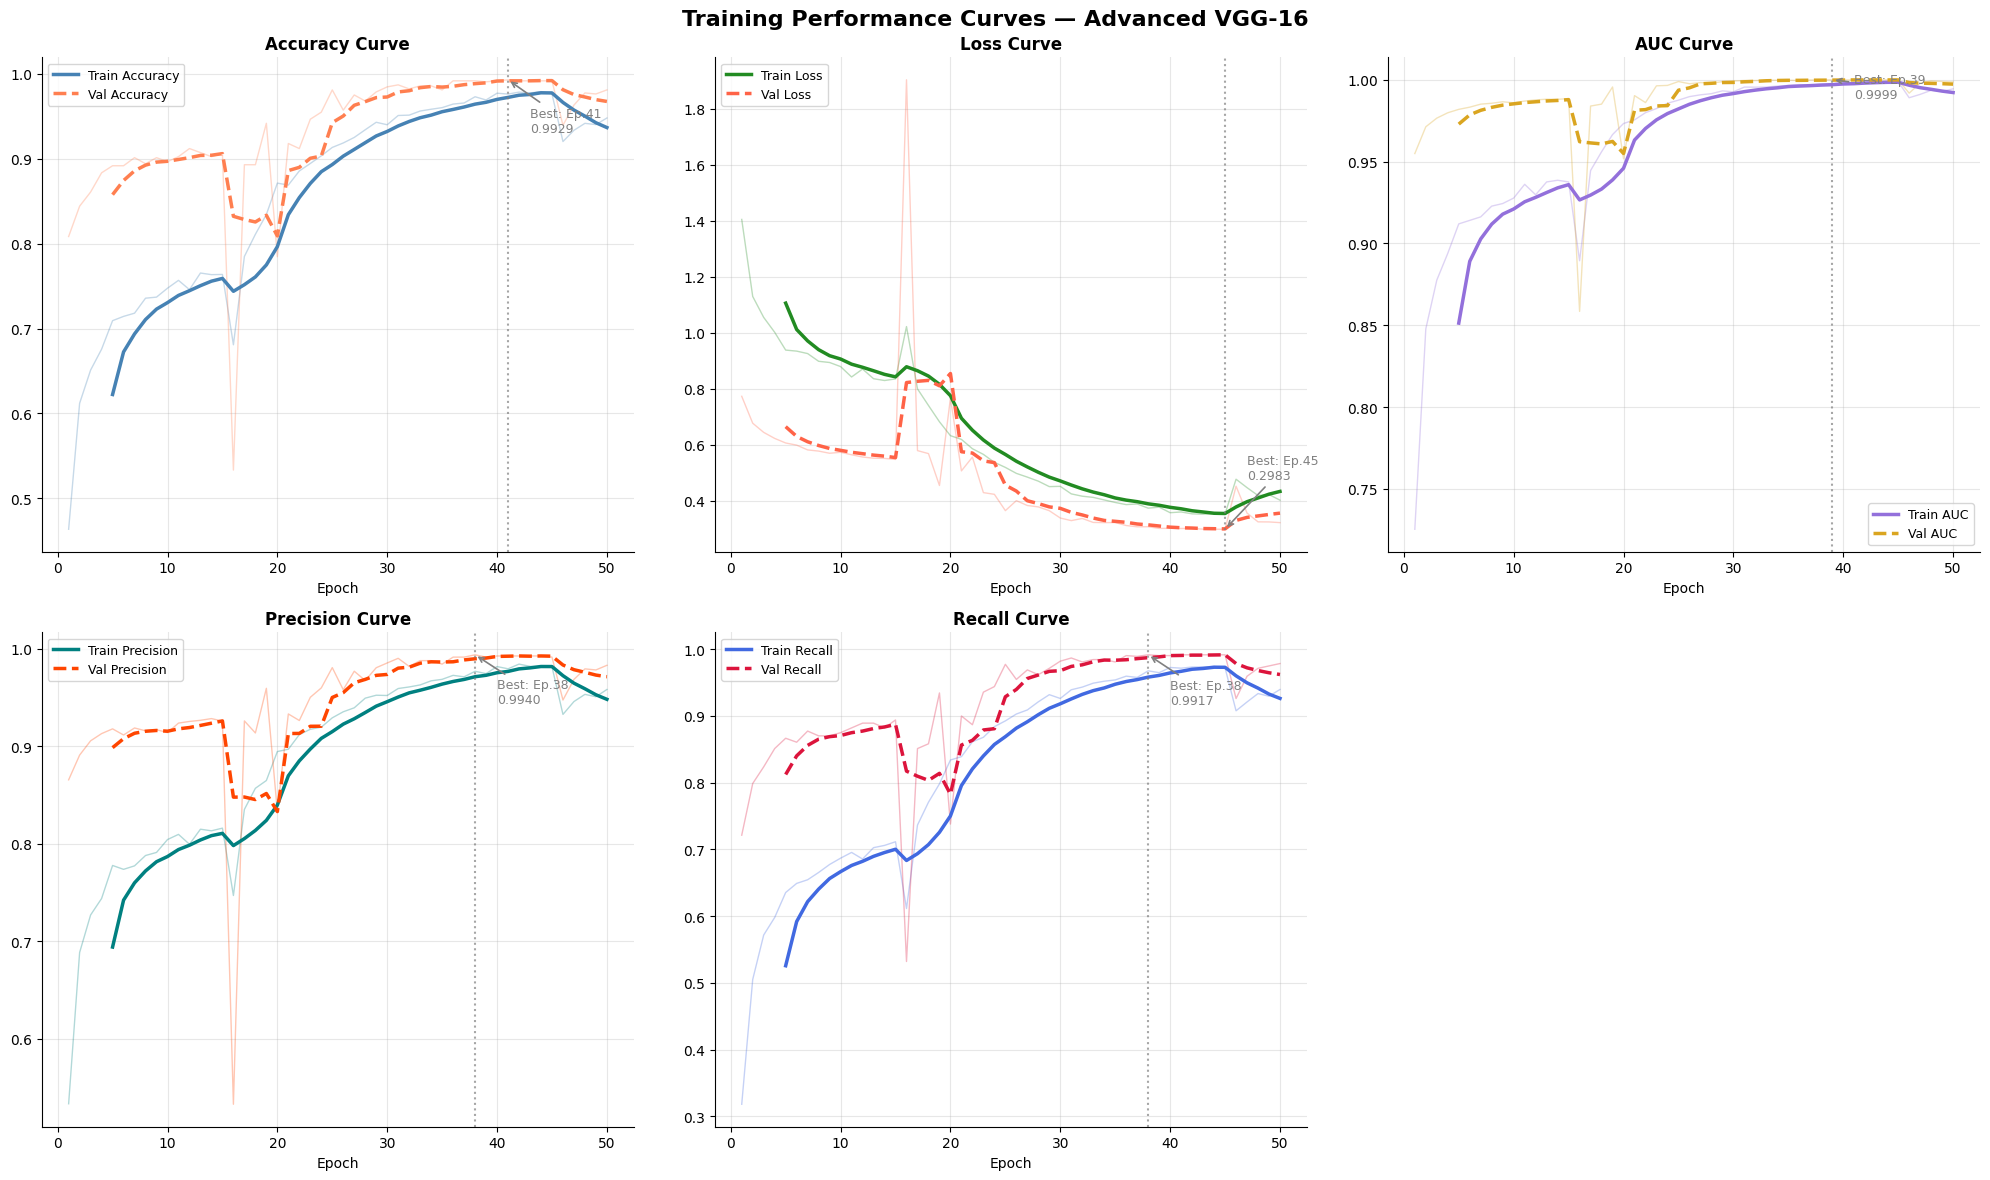

In [ ]:
def plot_training_history(history: dict, save_path: str = None):
    """Comprehensive training curves with moving average."""
    fig, axes = plt.subplots(2, 3, figsize=(20, 12))
    fig.suptitle('Training Performance Curves — Advanced VGG-16',
                 fontsize=16, fontweight='bold')

    metrics = [
        ('accuracy',  'val_accuracy',  'Accuracy',  'steelblue',    'coral'),
        ('loss',      'val_loss',      'Loss',      'forestgreen',  'tomato'),
        ('auc',       'val_auc',       'AUC',       'mediumpurple', 'goldenrod'),
        ('precision', 'val_precision', 'Precision', 'teal',         'orangered'),
        ('recall',    'val_recall',    'Recall',    'royalblue',    'crimson'),
    ]

    def moving_avg(x, w=5):
        return np.convolve(x, np.ones(w)/w, mode='valid')

    for ax, (tr_key, val_key, name, tc, vc) in zip(axes.flat, metrics):
        if tr_key not in history:
            ax.set_visible(False)
            continue
        tr = history[tr_key]
        vl = history.get(val_key, [])
        epochs_range = range(1, len(tr) + 1)

        ax.plot(epochs_range, tr, color=tc, alpha=0.3, linewidth=1)
        ax.plot(epochs_range, vl, color=vc, alpha=0.3, linewidth=1)

        if len(tr) >= 5:
            ax.plot(range(5, len(tr)+1), moving_avg(tr),
                    color=tc, linewidth=2.5, label=f'Train {name}')
        if len(vl) >= 5:
            ax.plot(range(5, len(vl)+1), moving_avg(vl),
                    color=vc, linewidth=2.5, linestyle='--', label=f'Val {name}')

        best_epoch = (np.argmin(vl) if 'loss' in tr_key else np.argmax(vl)) + 1 if vl else 1
        if vl:
            ax.axvline(best_epoch, color='gray', linestyle=':', alpha=0.7)
            ax.annotate(f'Best: Ep.{best_epoch}\n{vl[best_epoch-1]:.4f}',
                        xy=(best_epoch, vl[best_epoch-1]),
                        xytext=(best_epoch + 2, np.mean(vl)),
                        fontsize=9, color='gray',
                        arrowprops=dict(arrowstyle='->', color='gray', lw=1.2))

        ax.set_title(f'{name} Curve', fontsize=12, fontweight='bold')
        ax.set_xlabel('Epoch')
        ax.legend(fontsize=9)
        ax.grid(alpha=0.3)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    axes.flat[-1].set_visible(False)  # hide unused 6th subplot
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


plot_training_history(
    combined_history,
    save_path=f"{CFG.OUTPUT_DIR}/training_curves_vgg16.png"
)

## 🧪 Cell 15: Comprehensive Model Evaluation

In [ ]:
# Load best saved model
best_model = tf.keras.models.load_model(
    CFG.MODEL_PATH,
    custom_objects={'AdamW': AdamW}
)

# Predict on test set
y_true, y_pred_probs = [], []
class_to_idx = {c: i for i, c in enumerate(CFG.CLASSES)}

for X_batch, y_batch in tqdm(test_gen, desc='Predicting'):
    preds = best_model.predict(X_batch, verbose=0)
    y_pred_probs.extend(preds)
    y_true.extend(np.argmax(y_batch, axis=1))

y_true       = np.array(y_true)
y_pred_probs = np.array(y_pred_probs)
y_pred       = np.argmax(y_pred_probs, axis=1)

# ── Metrics ──
print('\n' + '='*60)
print('       CLASSIFICATION REPORT — VGG-16')
print('='*60)
print(classification_report(y_true, y_pred,
                              target_names=CFG.CLASSES, digits=4))

# Per-class AUC (one-vs-rest)
y_true_bin = label_binarize(y_true, classes=range(CFG.NUM_CLASSES))
print('Per-class AUC (OvR):')
for i, cls in enumerate(CFG.CLASSES):
    auc = roc_auc_score(y_true_bin[:, i], y_pred_probs[:, i])
    print(f'  {cls:15s}: {auc:.4f}')

macro_auc = roc_auc_score(y_true_bin, y_pred_probs, average='macro')
print(f'  {"Macro AUC":15s}: {macro_auc:.4f}')

Predicting:   0%|          | 0/100 [00:00<?, ?it/s]


       CLASSIFICATION REPORT — VGG-16
              precision    recall  f1-score   support

      glioma     0.9888    0.8825    0.9326       400
  meningioma     0.9292    0.9850    0.9563       400
     notumor     0.9569    1.0000    0.9780       400
   pituitary     0.9900    0.9925    0.9913       400

    accuracy                         0.9650      1600
   macro avg     0.9663    0.9650    0.9645      1600
weighted avg     0.9663    0.9650    0.9645      1600

Per-class AUC (OvR):
  glioma         : 0.9579
  meningioma     : 0.9957
  notumor        : 0.9973
  pituitary      : 0.9998
  Macro AUC      : 0.9877


## 🗺️ Cell 16: Confusion Matrix

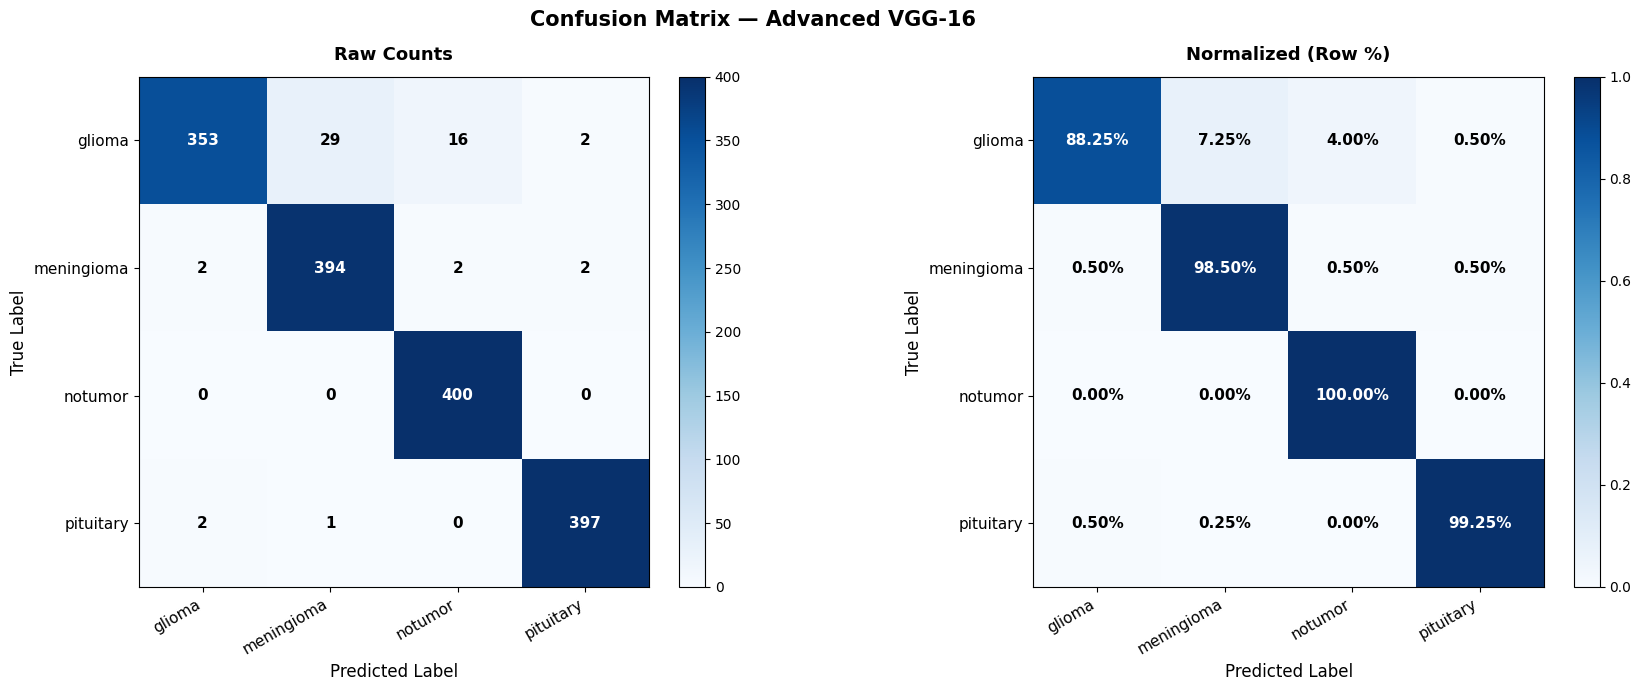

In [ ]:
def plot_confusion_matrix(y_true, y_pred, classes: list, save_path: str = None):
    """Beautiful confusion matrix with raw counts and percentages."""
    cm            = confusion_matrix(y_true, y_pred)
    cm_normalized = cm.astype('float') / cm.sum(axis=1, keepdims=True)

    fig, axes = plt.subplots(1, 2, figsize=(18, 7))
    fig.suptitle('Confusion Matrix — Advanced VGG-16',
                 fontsize=15, fontweight='bold')

    for ax, data, title, fmt in zip(
        axes,
        [cm, cm_normalized],
        ['Raw Counts', 'Normalized (Row %)'],
        ['d', '.2%']
    ):
        im = ax.imshow(data, interpolation='nearest', cmap='Blues')
        ax.set_title(title, fontsize=13, fontweight='bold', pad=12)
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

        tick_marks = np.arange(len(classes))
        ax.set_xticks(tick_marks)
        ax.set_yticks(tick_marks)
        ax.set_xticklabels(classes, rotation=30, ha='right', fontsize=11)
        ax.set_yticklabels(classes, fontsize=11)

        thresh = data.max() / 2.0
        for i in range(data.shape[0]):
            for j in range(data.shape[1]):
                val   = data[i, j]
                color = 'white' if val > thresh else 'black'
                ax.text(j, i, format(val, fmt), ha='center', va='center',
                        color=color, fontsize=11, fontweight='bold')

        ax.set_ylabel('True Label', fontsize=12)
        ax.set_xlabel('Predicted Label', fontsize=12)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


plot_confusion_matrix(
    y_true, y_pred, CFG.CLASSES,
    save_path=f"{CFG.OUTPUT_DIR}/confusion_matrix_vgg16.png"
)

## 📉 Cell 17: ROC Curves & Precision-Recall Curves

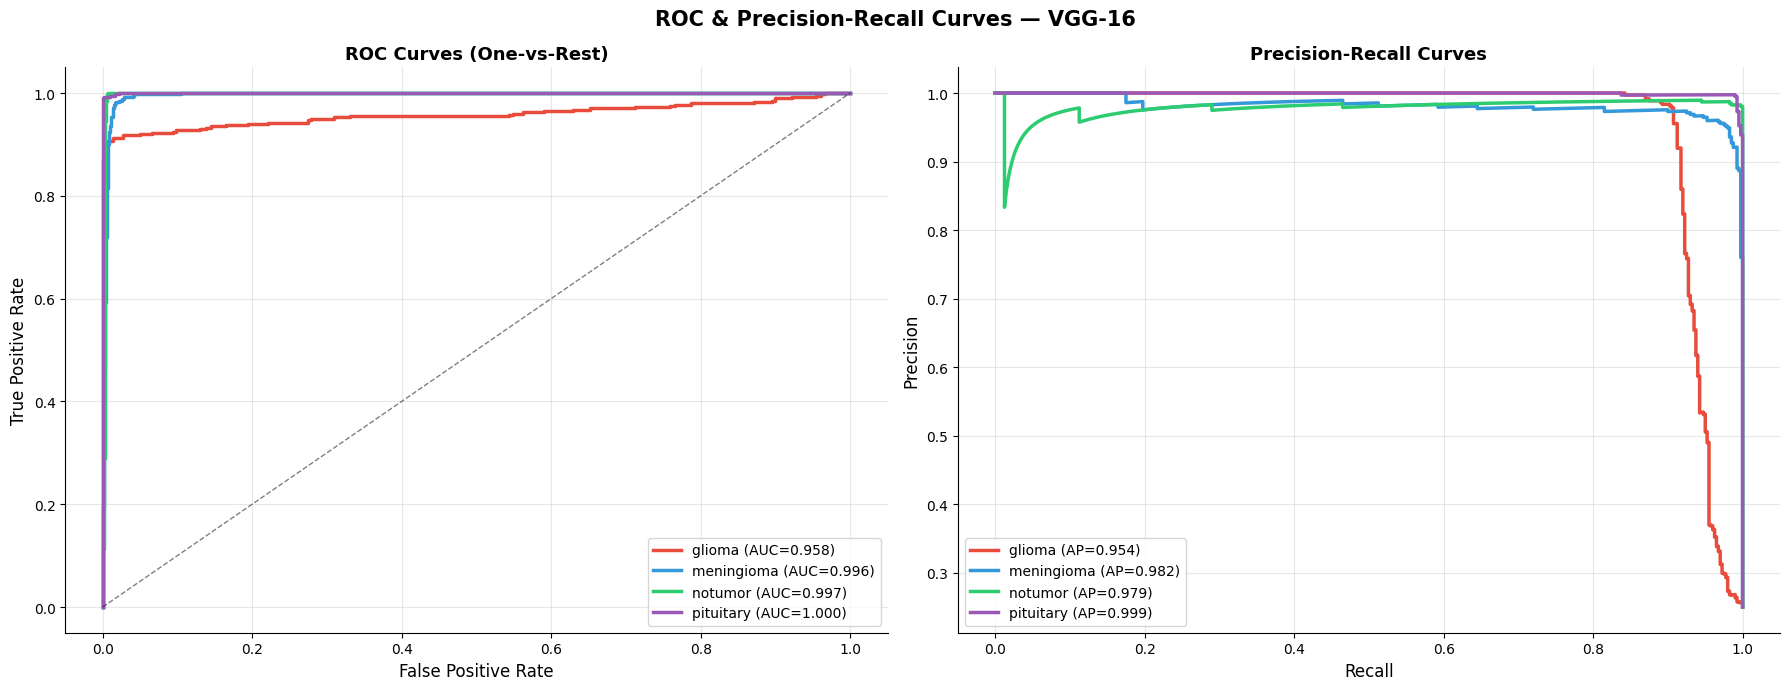

In [ ]:
def plot_roc_pr_curves(y_true_bin, y_pred_probs, classes: list, save_path: str = None):
    """Multi-class ROC and PR curves with AUC scores."""
    colors = ['#E74C3C', '#3498DB', '#2ECC71', '#9B59B6']
    fig, axes = plt.subplots(1, 2, figsize=(18, 7))
    fig.suptitle('ROC & Precision-Recall Curves — VGG-16',
                 fontsize=15, fontweight='bold')

    # ── ROC Curves ──
    ax = axes[0]
    for i, (cls, color) in enumerate(zip(classes, colors)):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_probs[:, i])
        auc = roc_auc_score(y_true_bin[:, i], y_pred_probs[:, i])
        ax.plot(fpr, tpr, color=color, linewidth=2.5, label=f'{cls} (AUC={auc:.3f})')
    ax.plot([0, 1], [0, 1], 'k--', linewidth=1, alpha=0.5)
    ax.set_xlabel('False Positive Rate', fontsize=12)
    ax.set_ylabel('True Positive Rate', fontsize=12)
    ax.set_title('ROC Curves (One-vs-Rest)', fontsize=13, fontweight='bold')
    ax.legend(loc='lower right', fontsize=10)
    ax.grid(alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # ── PR Curves ──
    ax = axes[1]
    for i, (cls, color) in enumerate(zip(classes, colors)):
        precision, recall, _ = precision_recall_curve(
            y_true_bin[:, i], y_pred_probs[:, i]
        )
        ap = average_precision_score(y_true_bin[:, i], y_pred_probs[:, i])
        ax.plot(recall, precision, color=color, linewidth=2.5,
                label=f'{cls} (AP={ap:.3f})')
    ax.set_xlabel('Recall', fontsize=12)
    ax.set_ylabel('Precision', fontsize=12)
    ax.set_title('Precision-Recall Curves', fontsize=13, fontweight='bold')
    ax.legend(loc='lower left', fontsize=10)
    ax.grid(alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


plot_roc_pr_curves(
    y_true_bin, y_pred_probs, CFG.CLASSES,
    save_path=f"{CFG.OUTPUT_DIR}/roc_pr_curves_vgg16.png"
)

## 🔥 Cell 18: GradCAM & GradCAM++ Visualization

All layers in best_model:
  [  0] input_image                                   N/A
  [  1] block1_conv1                                  N/A
  [  2] block1_conv2                                  N/A
  [  3] block1_pool                                   N/A
  [  4] block2_conv1                                  N/A
  [  5] block2_conv2                                  N/A
  [  6] block2_pool                                   N/A
  [  7] block3_conv1                                  N/A
  [  8] block3_conv2                                  N/A
  [  9] block3_conv3                                  N/A
  [ 10] block3_pool                                   N/A
  [ 11] block4_conv1                                  N/A
  [ 12] block4_conv2                                  N/A
  [ 13] block4_conv3                                  N/A
  [ 14] block4_pool                                   N/A
  [ 15] block5_conv1                                  N/A
  [ 16] block5_conv2                          

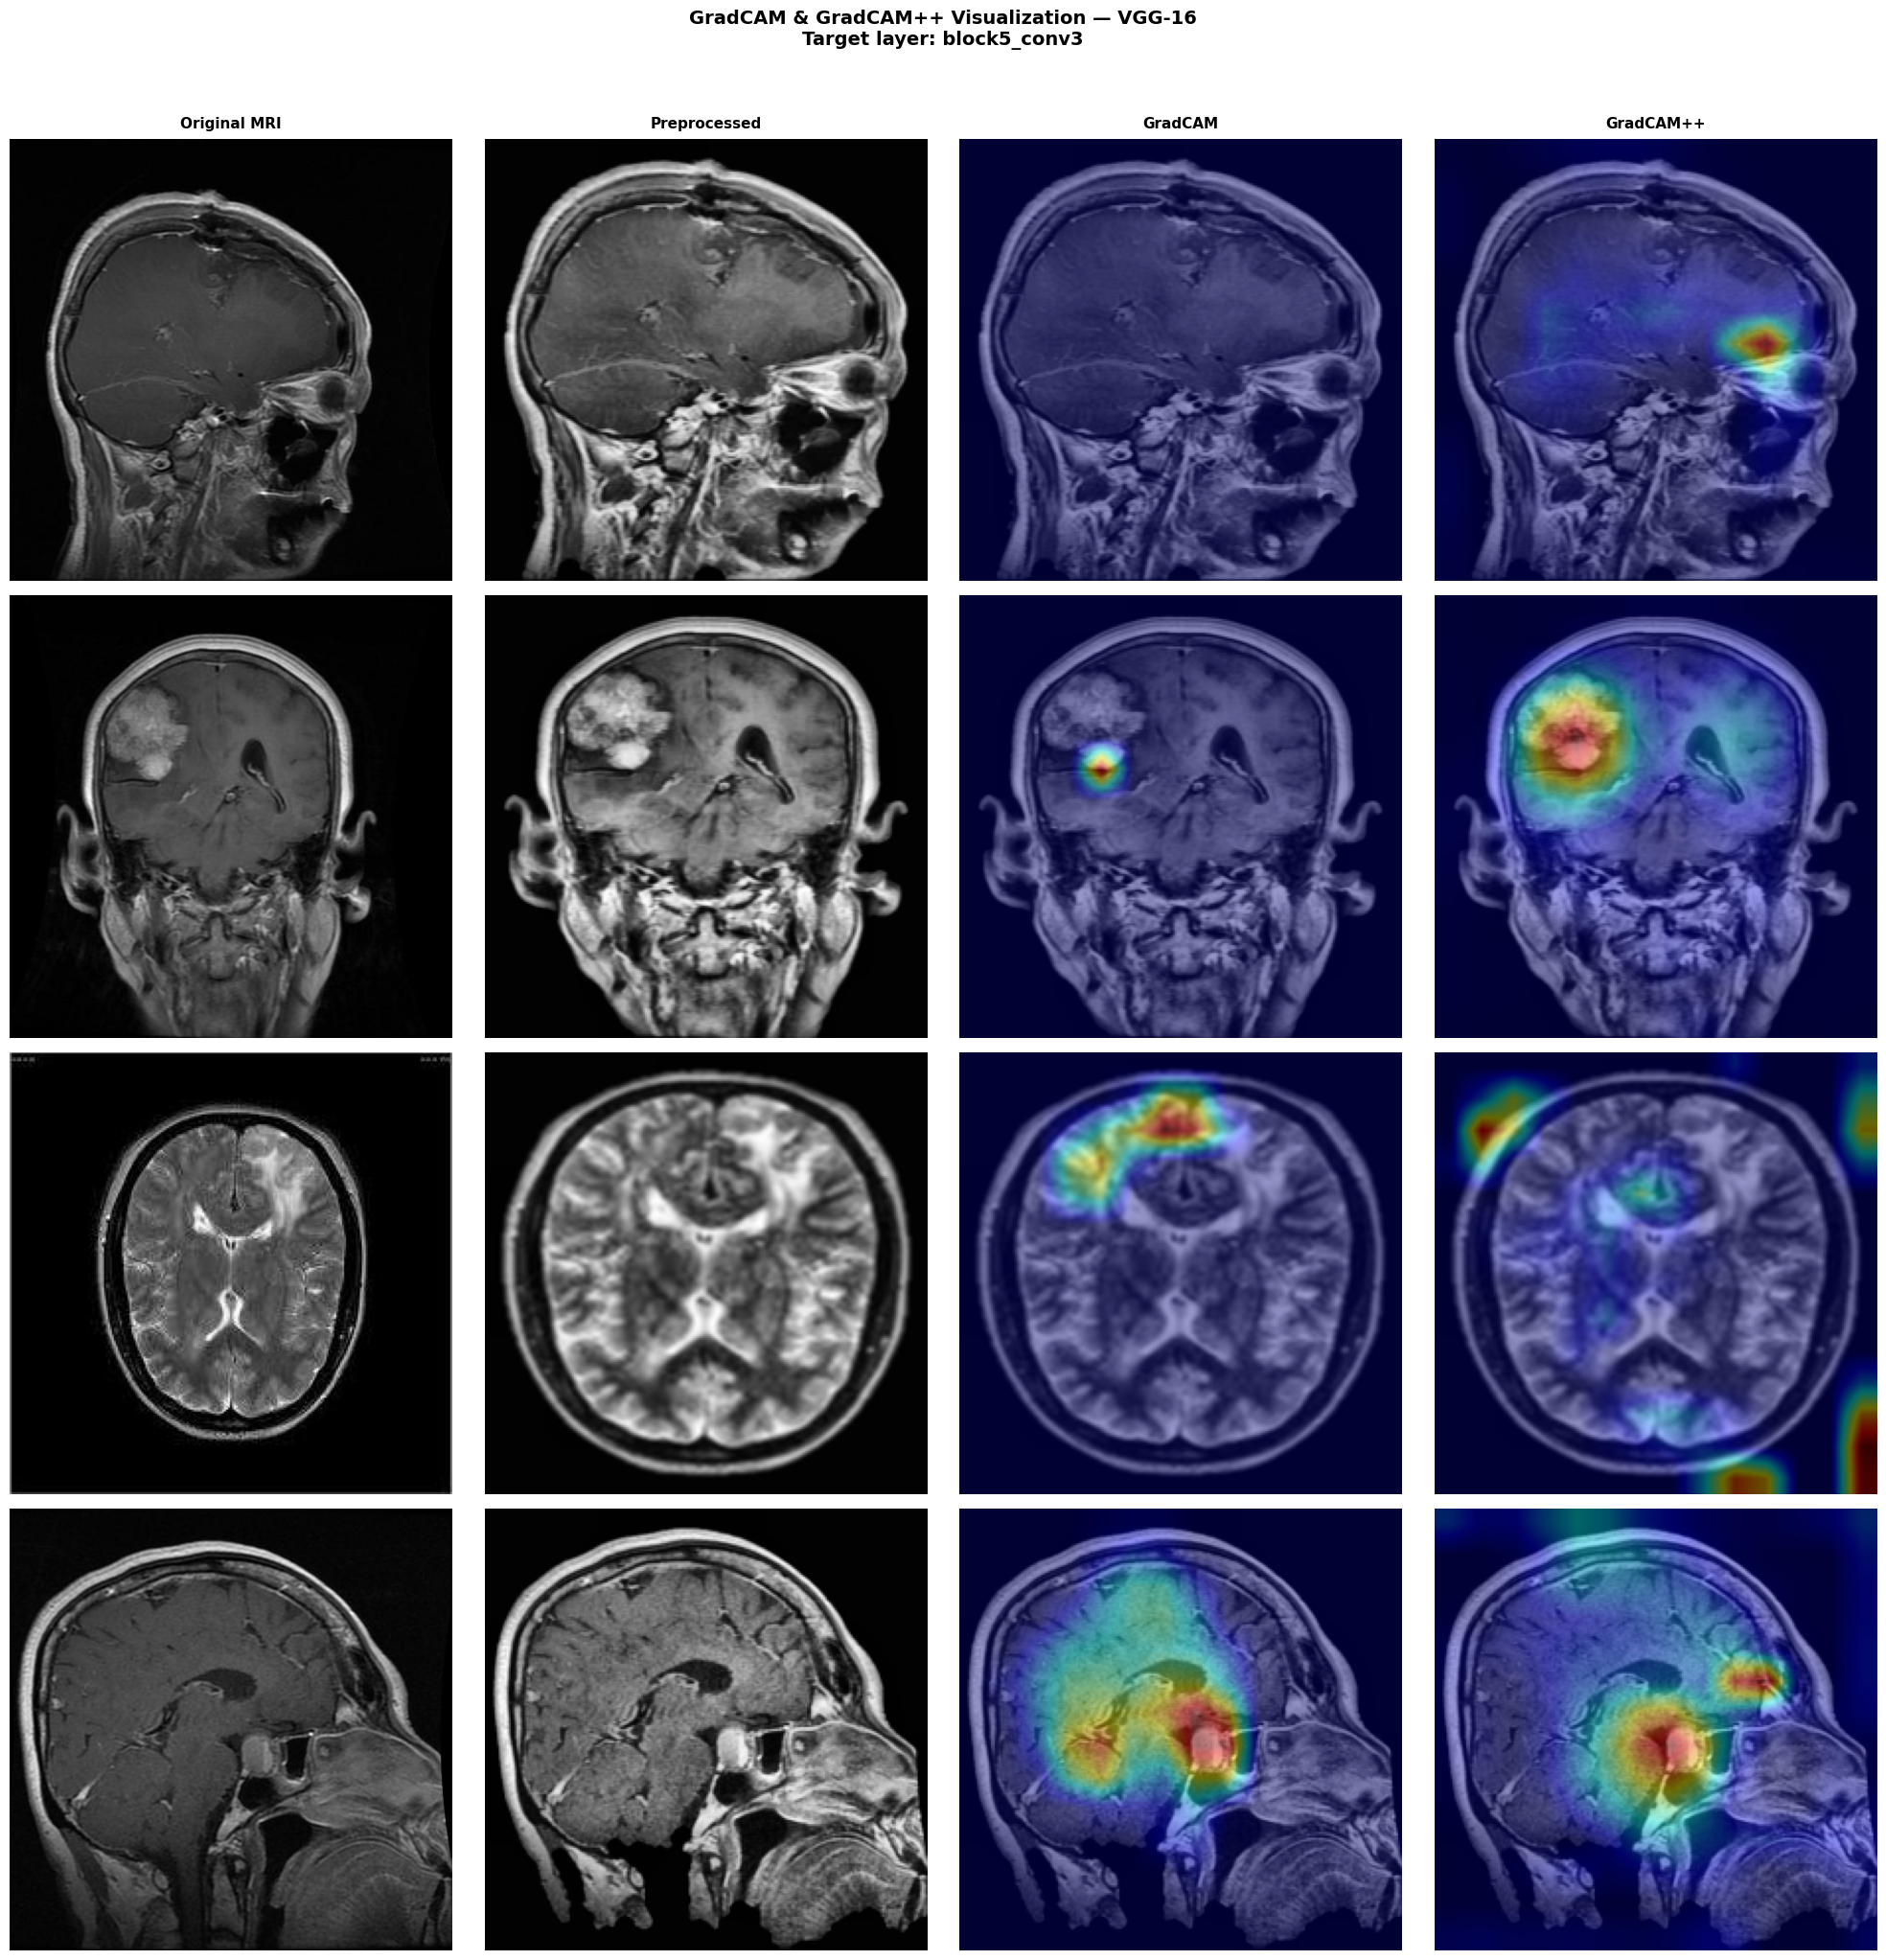

In [ ]:
# ══════════════════════════════════════════════════
#  CELL 18 — GradCAM & GradCAM++ for VGG-16
# ══════════════════════════════════════════════════
#
# VGG-16 GradCAM note:
#   Best target layer = 'block5_conv3'
#   → Last conv layer, spatial resolution 14×14
#   → Rich high-level features, good localization
#   Alternative: 'block4_conv3' (28×28, finer but less semantic)
#

# ── Step 1: Print all VGG-16 layer names ──
print('All layers in best_model:')
print('=' * 60)
for i, layer in enumerate(best_model.layers):
    try:
        shape = str(layer.output_shape)
    except Exception:
        shape = 'N/A'
    print(f'  [{i:3d}] {layer.name:<45} {shape}')
print('=' * 60)


def find_last_conv_layer(model):
    """Find last 4D spatial output layer (for GradCAM)."""
    candidate = None
    for layer in model.layers:
        try:
            shape = layer.output_shape
            if isinstance(shape, tuple) and len(shape) == 4:
                if shape[1] is not None and shape[1] > 1:
                    candidate = layer.name
        except Exception:
            continue
    return candidate


def get_gradcam_layer(model):
    """Returns best GradCAM target layer for VGG-16."""
    # VGG-16 specific names (in priority order)
    vgg16_candidates = [
        'block5_conv3',   # ← Best: last conv, 14×14 spatial, rich semantics
        'block5_conv2',
        'block5_conv1',
        'block4_conv3',   # ← Alternative: 28×28 resolution
    ]
    layer_names = {l.name for l in model.layers}
    for name in vgg16_candidates:
        if name in layer_names:
            print(f'✅ Using VGG-16 GradCAM layer: {name}')
            return name
    # Fallback: smart scan
    found = find_last_conv_layer(model)
    print(f'✅ Fallback scan found: {found}')
    return found


def make_gradcam_heatmap(img_array, model, layer_name, pred_index=None):
    """Generate GradCAM heatmap for a given image."""
    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads        = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap      = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap      = tf.squeeze(heatmap)
    heatmap      = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()


def make_gradcam_plus_plus(img_array, model, layer_name, pred_index=None):
    """GradCAM++ — improved weighting for better spatial coverage."""
    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(layer_name).output, model.output]
    )
    with tf.GradientTape() as tape2:
        with tf.GradientTape() as tape1:
            with tf.GradientTape() as tape0:
                conv_outputs, predictions = grad_model(img_array)
                if pred_index is None:
                    pred_index = tf.argmax(predictions[0])
                score = predictions[:, pred_index]
            grads1 = tape0.gradient(score, conv_outputs)
        grads2 = tape1.gradient(grads1, conv_outputs)
    grads3 = tape2.gradient(grads2, conv_outputs)

    conv_outputs = conv_outputs[0]
    grads1       = grads1[0]
    grads2       = grads2[0]
    grads3       = grads3[0]

    global_sum   = tf.reduce_sum(conv_outputs, axis=(0, 1), keepdims=True)
    alpha_num    = grads2
    alpha_denom  = 2 * grads2 + global_sum * grads3 + 1e-8
    alpha        = alpha_num / alpha_denom
    weights      = tf.reduce_sum(alpha * tf.nn.relu(grads1), axis=(0, 1))

    heatmap = tf.reduce_sum(weights * conv_outputs, axis=-1)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()


def overlay_heatmap(heatmap, image, alpha=0.4, colormap=cv2.COLORMAP_JET):
    """Resize heatmap and overlay on original image."""
    heatmap_resized = cv2.resize(heatmap, (image.shape[1], image.shape[0]))
    heatmap_colored = cv2.applyColorMap(
        np.uint8(255 * heatmap_resized), colormap
    )
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)
    superimposed    = heatmap_colored * alpha + (image * 255) * (1 - alpha)
    return np.clip(superimposed, 0, 255).astype(np.uint8)


def visualize_gradcam_vgg16(model, test_df, preprocessor, cfg, n_samples=4):
    """Visualize GradCAM and GradCAM++ for VGG-16 predictions."""
    layer_name = get_gradcam_layer(model)

    samples = test_df.groupby('label').first().reset_index()
    n = min(n_samples, len(samples))

    fig, axes = plt.subplots(n, 4, figsize=(20, n * 5))
    fig.suptitle(f'GradCAM & GradCAM++ Visualization — VGG-16\n'
                 f'Target layer: {layer_name}',
                 fontsize=14, fontweight='bold', y=1.02)

    col_titles = ['Original MRI', 'Preprocessed', 'GradCAM', 'GradCAM++']

    for i, (_, row) in enumerate(samples.iterrows()):
        if i >= n:
            break

        img_orig = cv2.cvtColor(cv2.imread(row['path']), cv2.COLOR_BGR2RGB)
        img_proc = preprocessor.preprocess(row['path'])
        img_inp  = vgg16_preprocess(img_proc * 255)
        img_inp  = np.expand_dims(img_inp, axis=0).astype(np.float32)

        probs      = model.predict(img_inp, verbose=0)[0]
        pred_idx   = np.argmax(probs)
        pred_label = cfg.CLASSES[pred_idx]
        true_label = row['label']
        correct    = '✓' if pred_label == true_label else '✗'

        heatmap_gc   = make_gradcam_heatmap(img_inp, model, layer_name, pred_idx)
        heatmap_gcpp = make_gradcam_plus_plus(img_inp, model, layer_name, pred_idx)

        overlay_gc   = overlay_heatmap(heatmap_gc,   img_proc)
        overlay_gcpp = overlay_heatmap(heatmap_gcpp, img_proc)

        ax_row = axes[i] if n > 1 else axes
        imgs   = [img_orig, img_proc, overlay_gc, overlay_gcpp]

        for j, (ax, im) in enumerate(zip(ax_row, imgs)):
            ax.imshow(im)
            if i == 0:
                ax.set_title(col_titles[j], fontsize=11, fontweight='bold', pad=8)
            if j == 0:
                ax.set_ylabel(
                    f'True: {true_label}\nPred: {pred_label} {correct}\n'
                    f'Conf: {probs[pred_idx]:.2%}',
                    fontsize=9, rotation=0, labelpad=80
                )
            ax.axis('off')

    plt.tight_layout()
    plt.savefig(f"{cfg.OUTPUT_DIR}/gradcam_vgg16.png", dpi=150, bbox_inches='tight')
    plt.show()


visualize_gradcam_vgg16(best_model, test_df, preprocessor, CFG, n_samples=4)

## 🟣 Cell 19: LIME Explainability

## 📊 Cell 22: Statistical Analysis

In [ ]:
from statsmodels.stats.proportion import proportion_confint


def compute_performance_summary(y_true, y_pred, y_probs, class_names) -> pd.DataFrame:
    """Generate per-class and overall performance stats with 95% CIs."""
    rows = []
    y_true_bin = label_binarize(y_true, classes=range(len(class_names)))

    for i, cls in enumerate(class_names):
        y_t = (y_true == i).astype(int)
        y_p = (y_pred == i).astype(int)

        tp = np.sum((y_t == 1) & (y_p == 1))
        fp = np.sum((y_t == 0) & (y_p == 1))
        fn = np.sum((y_t == 1) & (y_p == 0))
        tn = np.sum((y_t == 0) & (y_p == 0))
        n  = len(y_t)

        prec = tp / (tp + fp + 1e-9)
        rec  = tp / (tp + fn + 1e-9)
        spec = tn / (tn + fp + 1e-9)
        f1   = 2 * prec * rec / (prec + rec + 1e-9)
        acc  = (tp + tn) / n
        auc  = roc_auc_score(y_true_bin[:, i], y_probs[:, i])

        ci_lo, ci_hi = proportion_confint(
            int(acc * n), n, alpha=0.05, method='wilson'
        )
        rows.append({
            'Class':       cls,
            'Precision':   f'{prec:.4f}',
            'Recall':      f'{rec:.4f}',
            'Specificity': f'{spec:.4f}',
            'F1-Score':    f'{f1:.4f}',
            'Accuracy':    f'{acc:.4f}',
            'AUC':         f'{auc:.4f}',
            '95% CI (Acc)': f'[{ci_lo:.4f}, {ci_hi:.4f}]'
        })

    overall_acc = np.mean(y_true == y_pred)
    ci_lo, ci_hi = proportion_confint(
        int(overall_acc * len(y_true)), len(y_true),
        alpha=0.05, method='wilson'
    )
    macro_auc = roc_auc_score(y_true_bin, y_probs, average='macro')
    macro_f1  = f1_score(y_true, y_pred, average='macro')

    rows.append({
        'Class':       'MACRO AVG',
        'Precision':   '',
        'Recall':      '',
        'Specificity': '',
        'F1-Score':    f'{macro_f1:.4f}',
        'Accuracy':    f'{overall_acc:.4f}',
        'AUC':         f'{macro_auc:.4f}',
        '95% CI (Acc)': f'[{ci_lo:.4f}, {ci_hi:.4f}]'
    })

    summary_df = pd.DataFrame(rows)
    print('\nPerformance Summary — VGG-16 Brain Tumor Classifier')
    print('=' * 90)
    print(summary_df.to_string(index=False))
    summary_df.to_csv(f"{CFG.OUTPUT_DIR}/performance_summary_vgg16.csv", index=False)
    return summary_df


summary_df = compute_performance_summary(
    y_true, y_pred, y_pred_probs, CFG.CLASSES
)


Performance Summary — VGG-16 Brain Tumor Classifier
     Class Precision Recall Specificity F1-Score Accuracy    AUC     95% CI (Acc)
    glioma    0.9888 0.8825      0.9967   0.9326   0.9681 0.9579 [0.9583, 0.9757]
meningioma    0.9292 0.9850      0.9750   0.9563   0.9775 0.9957 [0.9690, 0.9837]
   notumor    0.9569 1.0000      0.9850   0.9780   0.9888 0.9973 [0.9823, 0.9929]
 pituitary    0.9900 0.9925      0.9967   0.9913   0.9956 0.9998 [0.9910, 0.9979]
 MACRO AVG                                0.9645   0.9650 0.9877 [0.9548, 0.9729]


## 🔍 Cell 23: Error Analysis — Misclassification Inspection

Total misclassified: 56 / 1600 (3.50%)


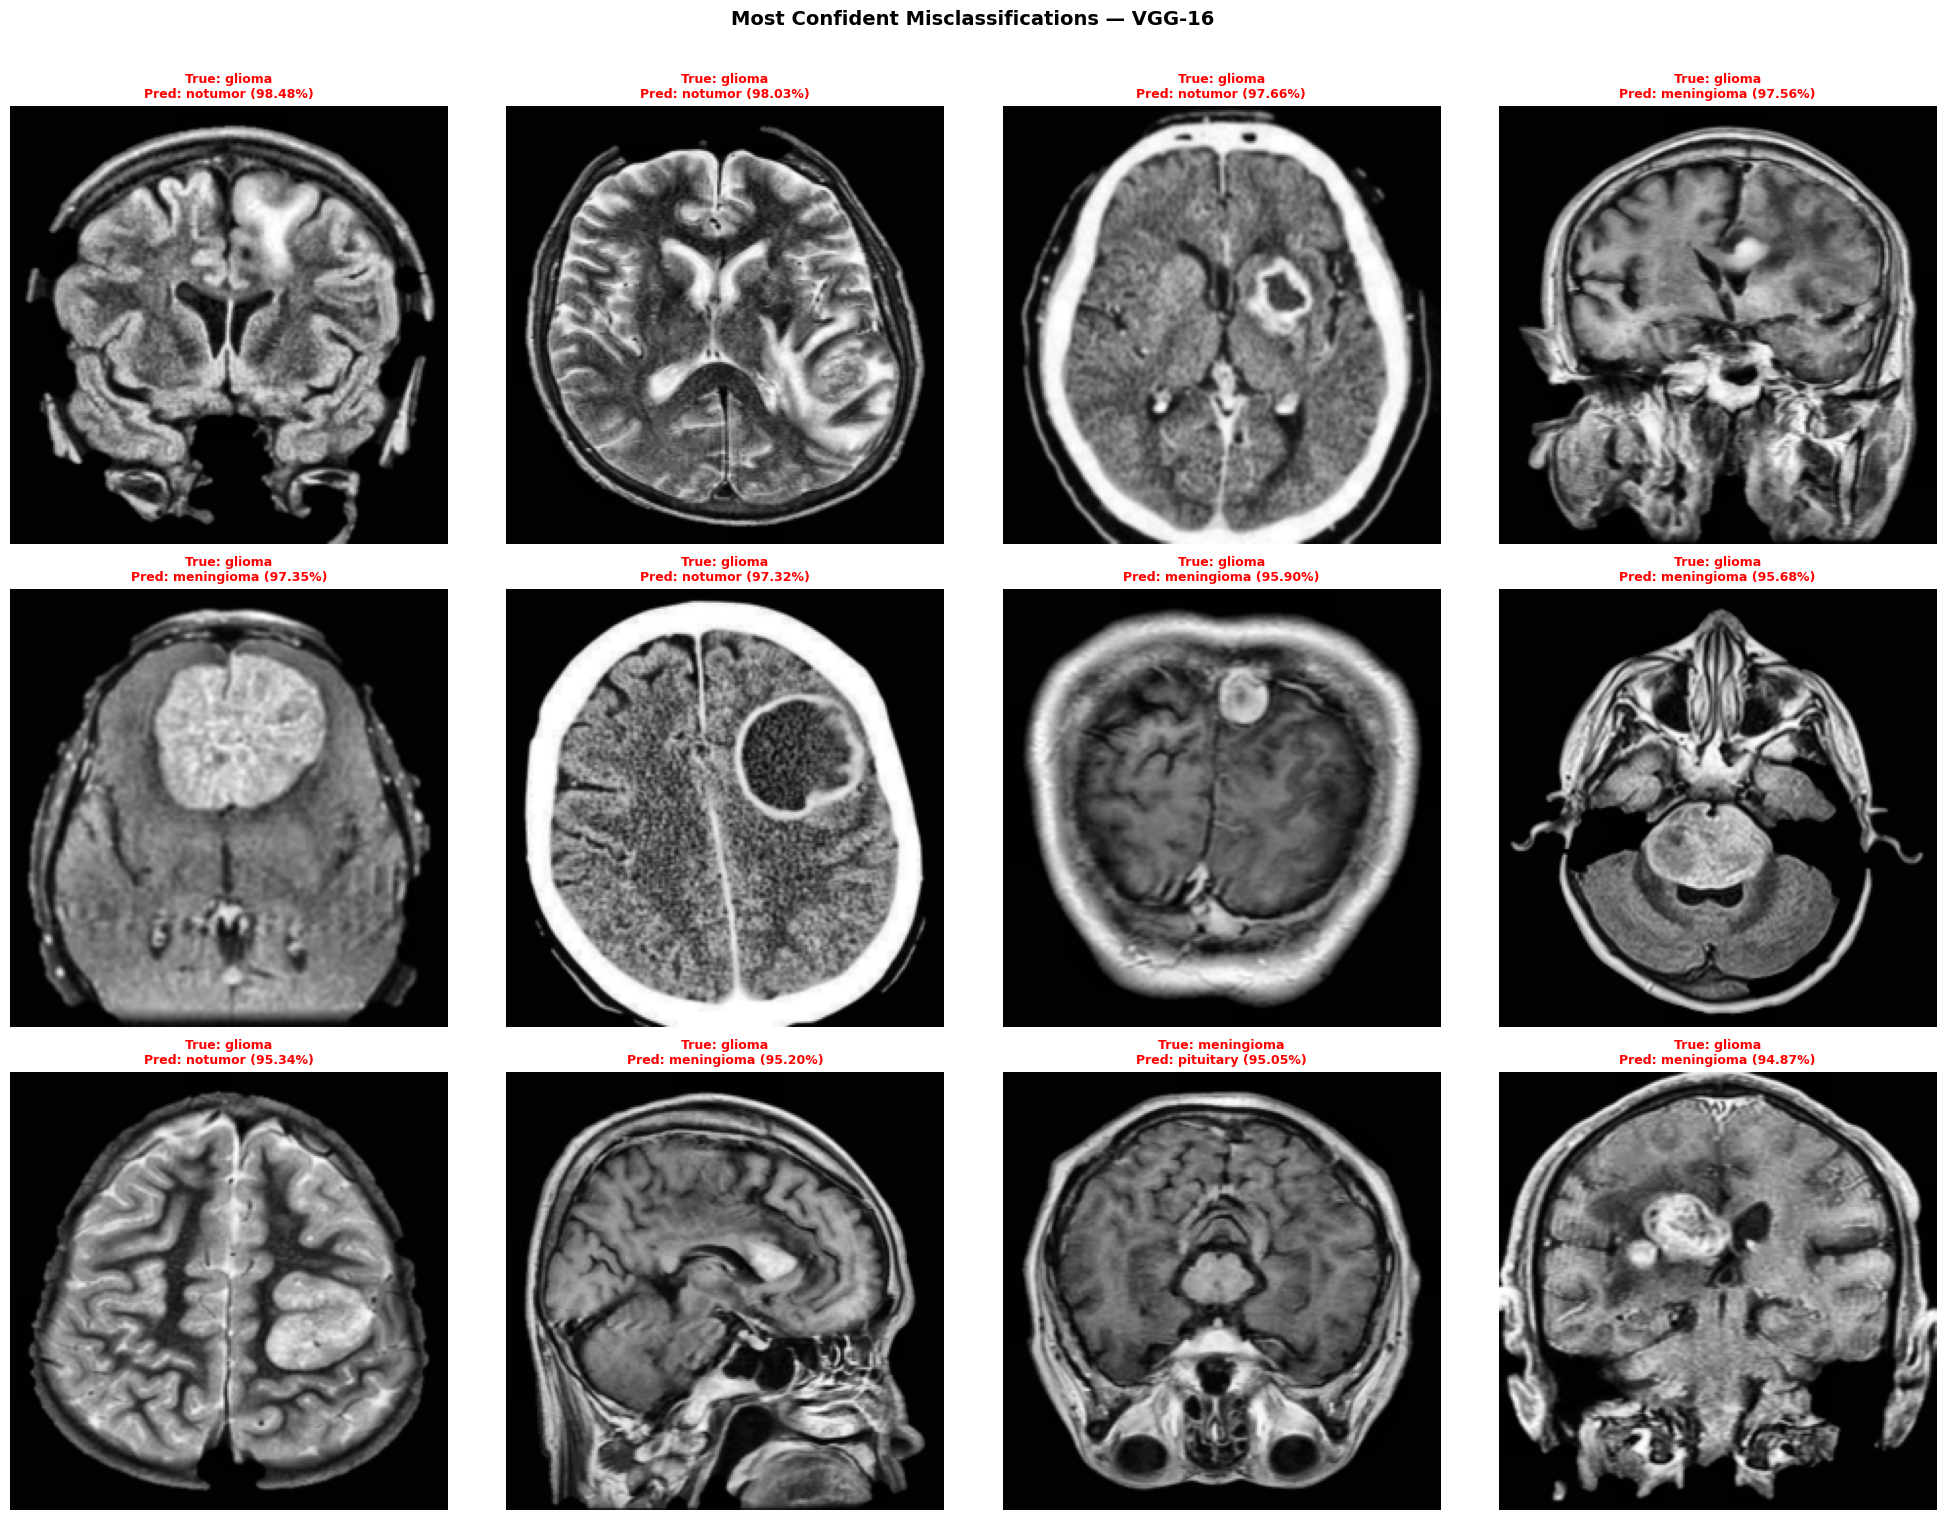

In [ ]:
def analyze_misclassifications(test_df, y_true, y_pred, y_probs,
                                 class_names, preprocessor,
                                 n_display=3, save_path=None):
    """Visualize most confident misclassifications (VGG-16)."""
    error_indices = np.where(y_true != y_pred)[0]

    if len(error_indices) == 0:
        print('✅ No misclassifications — perfect test accuracy!')
        return

    print(f'Total misclassified: {len(error_indices)} / {len(y_true)} '
          f'({len(error_indices)/len(y_true):.2%})')

    wrong_confidences = y_probs[error_indices, y_pred[error_indices]]
    sorted_idx        = error_indices[np.argsort(-wrong_confidences)]
    n_show            = min(len(sorted_idx), n_display * 4)
    top_errors        = sorted_idx[:n_show]

    cols = 4
    rows = int(np.ceil(n_show / cols))

    fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 5))
    fig.suptitle('Most Confident Misclassifications — VGG-16',
                 fontsize=14, fontweight='bold', y=1.01)

    axes_list = list(axes.flat) if rows > 1 else list(axes)

    for ax_i, err_idx in enumerate(top_errors):
        ax       = axes_list[ax_i]
        row_data = test_df.iloc[err_idx]
        img      = preprocessor.preprocess(row_data['path'])
        true_lbl = class_names[y_true[err_idx]]
        pred_lbl = class_names[y_pred[err_idx]]
        conf     = y_probs[err_idx, y_pred[err_idx]]

        ax.imshow(img)
        ax.set_title(
            f'True: {true_lbl}\nPred: {pred_lbl} ({conf:.2%})',
            fontsize=9, color='red', fontweight='bold'
        )
        ax.axis('off')

    for ax in axes_list[n_show:]:
        ax.set_visible(False)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


analyze_misclassifications(
    test_df, y_true, y_pred, y_pred_probs, CFG.CLASSES,
    preprocessor, n_display=3,
    save_path=f"{CFG.OUTPUT_DIR}/misclassifications_vgg16.png"
)

## 🏁 Cell 24: Final Results Dashboard

## 💾 Cell 25: Model Export & Inference Function

In [ ]:
def export_to_tflite(model: Model, output_path: str, quantize: bool = True):
    """Export VGG-16 model to TFLite with optional FP16 quantization."""
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    if quantize:
        converter.optimizations       = [tf.lite.Optimize.DEFAULT]
        converter.target_spec.supported_types = [tf.float16]
    tflite_model = converter.convert()
    with open(output_path, 'wb') as f:
        f.write(tflite_model)
    size_mb = os.path.getsize(output_path) / (1024 ** 2)
    print(f'✅ TFLite model saved: {output_path} ({size_mb:.2f} MB)')


export_to_tflite(
    best_model,
    f"{CFG.OUTPUT_DIR}/vgg16_brain_tumor_fp16.tflite",
    quantize=True
)


def predict_single_image(image_path: str, model: Model,
                           preprocessor: AdvancedPreprocessor,
                           class_names: list, cfg: CFG) -> dict:
    """
    Single-image clinical inference for VGG-16.
    Uses vgg16_preprocess (not mobilenet_preprocess).
    """
    img  = preprocessor.preprocess(image_path)
    inp  = vgg16_preprocess(img * 255).astype(np.float32)
    probs     = model.predict(inp[np.newaxis], verbose=0)[0]
    pred_idx  = np.argmax(probs)
    pred_cls  = class_names[pred_idx]
    conf      = probs[pred_idx]

    print(f'\n📋 VGG-16 Prediction Report')
    print(f'   Image      : {os.path.basename(image_path)}')
    print(f'   Predicted  : {pred_cls.upper()}')
    print(f'   Confidence : {conf:.4f} ({conf*100:.2f}%)')
    print(f'   All probs  :')
    for cls, p in zip(class_names, probs):
        bar = '█' * int(p * 30)
        print(f'     {cls:15s} {bar:30s} {p:.4f}')

    return {'predicted_class': pred_cls, 'confidence': float(conf),
            'all_probabilities': dict(zip(class_names, probs.tolist())),
            'processed_image': img}

Saved artifact at '/tmp/tmplxcne3ih'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_image')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  135439299224272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135439299222544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135439299229456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135439299221200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135439299226192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135439299231184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135439299221392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135439299216016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135439299219664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135439299227920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135439299229840

## 📋 Cell 26: Research Summary Report